# CF Thesis — Genotype-Phenotype Mapping in Cystic Fibrosis
## Data Cleaning
Sosnay et al. 2013 (Nature Genetics) — 159 CFTR variants from 39,696 patients


### Upload & imports


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()  # click "Choose File"

filename = list(uploaded.keys())[0]
print(f"Uploaded: {filename}")


Saving 41588_2013_BFng2745_MOESM35_ESM - PhenotypeSummaryTable.csv to 41588_2013_BFng2745_MOESM35_ESM - PhenotypeSummaryTable.csv
Uploaded: 41588_2013_BFng2745_MOESM35_ESM - PhenotypeSummaryTable.csv


### Load the raw data
Two header rows (rows 0-1), data starts at row 2.


In [ ]:
raw = pd.read_csv(filename, header=None, encoding="utf-8")

print(f"Rows: {raw.shape[0]}")
print(f"Columns: {raw.shape[1]}")
print()
print("First 3 rows (row 0 and 1 are headers, row 2 is first variant):")
raw.head(3)


Rows: 161
Columns: 31

First 3 rows (row 0 and 1 are headers, row 2 is first variant):


,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
0,Variant name - HGVS nomenclature,Protein name,Variant legacy name,dbSNP rsID \n(if available),Part of current ACMG list?,"# alleles in CFTR2 (79,392 total, 70,777 ident...","Allele freq. in CFTR2 (alleles/70,777)",Clinical analysis,NaN,NaN,...,Penetrance/population analysis,NaN,NaN,Computational Predictions,NaN,NaN,NaN,Final call,Microattribution,Researcher IDs for Microattribution
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mean sweat [Cl-] in CFTR2 (*insufficient/ inco...,n sweats from CFTR2,% of patients listed as PI,...,# times seen in fathers,# occurring in fathers in trans with an ACMG v...,"Freq. in fathers (2,148 fathers*2 = 4,296 alle...",POSE (score is proportional to impact of amino...,PolyPhen-2\n(HumVar),SIFT ...,PANTHER (Probability Damaging),NaN,NaN,NaN
2,c.948delT,p.Phe316LeufsX12,1078delT,rs121908744,No,105,0.0015,97,37,98.6%,...,4,NaN,0.00093,NaN,NaN,NaN,NaN,CF-causing,"Belgium, Bern (Switzerland), Canada, France, G...","F-9759-2012, D-2793-2012, C-6969-2012, D-1013-..."


### Drop headers, name columns


In [ ]:
# Remove first 2 rows which are the headers
df = raw.iloc[2:].copy()
df = df.reset_index(drop=True)

# The data has 31 collums
# We drop empty collums
df = df.iloc[:, :31]

# Now name the 31 columns
df.columns = [
    "variant_hgvs",           # 0  - variant name in HGVS format
    "protein_name",            # 1  - protein change
    "variant_legacy",          # 2  - old/common name
    "dbsnp_rsid",              # 3  - database ID
    "acmg_list",               # 4  - on ACMG list?
    "n_alleles",               # 5  - how many times seen in CFTR2
    "allele_freq",             # 6  - frequency in CFTR2
    "mean_sweat_cl",           # 7  - mean sweat chloride (mmol/L)
    "n_sweats",                # 8  - number of sweat tests
    "pi_percent",              # 9  - % patients with pancreatic insufficiency
    "n_pi_patients",           # 10 - number of PI patients
    "mean_fev1_pct_pred",      # 11 - mean lung function (FEV1 % predicted)
    "n_lung_function",         # 12 - number of lung function tests
    "pseudomonas_pct",         # 13 - % patients with Pseudomonas infection
    "n_pseudomonas",           # 14 - number of Pseudomonas patients
    "variant_type",            # 15 - type of mutation
    "variant_type_comments",   # 16 - comments on variant type
    "cl_conductance_pct_wt",   # 17 - chloride conductance (% of wild type)
    "cbc_hela_pct_wt",         # 18 - protein processing in HeLa cells (% WT)
    "cbc_frt_pct_wt",          # 19 - protein processing in FRT cells (% WT)
    "spliced_rna_pct_wt",      # 20 - correctly spliced RNA (% WT)
    "n_seen_in_fathers",       # 21 - times seen in fathers
    "n_fathers_trans_acmg",    # 22 - fathers in trans with ACMG variant
    "freq_in_fathers",         # 23 - frequency in fathers
    "pose_score",              # 24 - POSE prediction score
    "polyphen2",               # 25 - PolyPhen-2 prediction
    "sift",                    # 26 - SIFT prediction score
    "panther",                 # 27 - PANTHER prediction score
    "final_call",              # 28 - CF-causing / Indeterminate / Not CF-causing
    "microattribution",        # 29 - contributing countries
    "researcher_ids",          # 30 - researcher IDs
]

print(f"Data has {len(df)} variants and {len(df.columns)} columns")
print()
print("First 5 variants:")
df[["variant_hgvs", "variant_legacy", "variant_type", "final_call"]].head()


Data has 159 variants and 31 columns

First 5 variants:


,variant_hgvs,variant_legacy,variant_type,final_call
0,c.948delT,1078delT,ins/del (FS),CF-causing
1,c.1022_1023insTC,1154insTC,ins/del (FS),CF-causing
2,c.1081delT,1213delT,ins/del (FS),CF-causing
3,c.1116+1G>A,1248+1G->A,canonical splice,CF-causing
4,c.1127_1128insA,1259insA,ins/del (FS),CF-causing


### Clean variant names


In [ ]:
text_columns = ["variant_hgvs", "protein_name", "variant_legacy",
                "variant_type", "final_call"]

for col in text_columns:
    df[col] = df[col].astype(str).str.replace('\xa0', ' ', regex=False).str.strip()
    df[col] = df[col].replace('nan', np.nan)

print("Sample cleaned names:")
df[["variant_hgvs", "variant_legacy"]].head()


Sample cleaned names:


,variant_hgvs,variant_legacy
0,c.948delT,1078delT
1,c.1022_1023insTC,1154insTC
2,c.1081delT,1213delT
3,c.1116+1G>A,1248+1G->A
4,c.1127_1128insA,1259insA


### Fix clinical variables
Remove % signs, flag asterisked sweat Cl values, convert to numeric.


In [ ]:
# Remove "%" signs and convert to numbers
for col in ["mean_fev1_pct_pred", "pi_percent", "pseudomonas_pct"]:
    df[col] = df[col].astype(str)
    df[col] = df[col].str.replace('%', '')
    df[col] = df[col].str.strip()
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("FEV1 - first 5 values (should be numbers now):")
print(df["mean_fev1_pct_pred"].head().tolist())
print()

# Flag sweat Cl values with asterisks (insufficient data), then remove the asterisk
df["sweat_cl_flag"] = df["mean_sweat_cl"].astype(str).str.contains(r'\*', na=False)
print(f"Variants with insufficient sweat Cl data: {df['sweat_cl_flag'].sum()}")

df["mean_sweat_cl"] = df["mean_sweat_cl"].astype(str)
df["mean_sweat_cl"] = df["mean_sweat_cl"].str.replace('*', '', regex=False)
df["mean_sweat_cl"] = df["mean_sweat_cl"].str.strip()
df["mean_sweat_cl"] = pd.to_numeric(df["mean_sweat_cl"], errors='coerce')

print()
print("Clinical variables summary:")
df[["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct"]].describe().round(1)


FEV1 - first 5 values (should be numbers now):
[73.6, 72.7, 83.1, 58.1, 79.4]

Variants with insufficient sweat Cl data: 3

Clinical variables summary:


,mean_sweat_cl,pi_percent,mean_fev1_pct_pred,pseudomonas_pct
count,157.0,159.0,156.0,159.0
mean,92.9,77.2,76.1,50.4
std,18.0,30.1,10.9,23.7
min,39.0,0.0,43.2,0.0
25%,90.0,56.4,70.5,37.6
50%,99.0,95.7,74.6,51.9
75%,103.0,100.0,82.2,63.6
max,120.0,100.0,112.8,100.0


### Fix functional variables
Spliced RNA has censored "<10" values — replace with midpoint (5).


In [ ]:
# Convert the straightforward ones
for col in ["cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

# Handle spliced RNA censored values
df["spliced_rna_pct_wt"] = df["spliced_rna_pct_wt"].astype(str)
df["spliced_rna_pct_wt"] = df["spliced_rna_pct_wt"].str.replace('*', '', regex=False)

n_censored = df["spliced_rna_pct_wt"].str.contains('<', na=False).sum()
print(f"Spliced RNA: {n_censored} values were reported as '<10' (censored)")

# Replace "<10" with 5 (midpoint of 0-10 range)
df["spliced_rna_pct_wt"] = df["spliced_rna_pct_wt"].str.replace('<10', '5', regex=False)
df["spliced_rna_pct_wt"] = pd.to_numeric(df["spliced_rna_pct_wt"], errors='coerce')

print()
print("Functional variables summary:")
df[["cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt",
    "spliced_rna_pct_wt"]].describe().round(1)


Spliced RNA: 80 values were reported as '<10' (censored)

Functional variables summary:


,cl_conductance_pct_wt,cbc_hela_pct_wt,cbc_frt_pct_wt,spliced_rna_pct_wt
count,63.0,67.0,63.0,90.0
mean,25.8,57.0,64.4,5.4
std,41.9,44.1,43.3,7.1
min,0.0,0.0,0.0,0.0
25%,0.2,0.6,11.0,5.0
50%,3.1,89.3,86.0,5.0
75%,37.4,96.8,102.4,5.0
max,147.0,99.4,110.9,71.0


### Fix computational predictions


In [ ]:
# Convert numeric ones
for col in ["pose_score", "sift", "panther"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

# Encode PolyPhen-2
print("PolyPhen-2 original values:")
print(df["polyphen2"].value_counts())
print()

polyphen_mapping = {
    "Benign": 0,
    "Possibly damaging": 1,
    "Probably damaging": 2
}
df["polyphen2_encoded"] = df["polyphen2"].astype(str).str.strip().map(polyphen_mapping)

print("After encoding:")
df["polyphen2_encoded"].value_counts()


PolyPhen-2 original values:
polyphen2
Probably damaging    50
Benign                8
Possibly damaging     6
Name: count, dtype: int64

After encoding:


,count
polyphen2_encoded,
2.0,50
0.0,8
1.0,6


### Convert count columns


In [ ]:
count_columns = ["n_alleles", "allele_freq", "n_sweats", "n_pi_patients",
                 "n_lung_function", "n_pseudomonas", "n_seen_in_fathers",
                 "n_fathers_trans_acmg", "freq_in_fathers"]

for col in count_columns:
    df[col] = pd.to_numeric(df[col].astype(str).str.strip(), errors='coerce')

print("Done - count columns converted.")


Done - count columns converted.


### Encode variant type (one-hot)


In [ ]:
print("Original variant types:")
print(df["variant_type"].value_counts())
print()

# Map to cleaner names
type_mapping = {
    "ins/del (FS)":    "frameshift",
    "missense":        "missense",
    "nonsense":        "nonsense",
    "canonical splice":"canonical_splice",
    "splice (other)":  "splice_other",
    "ins/del (no FS)": "inframe_indel",
}
df["variant_type_clean"] = df["variant_type"].map(type_mapping)

print("Cleaned variant types:")
print(df["variant_type_clean"].value_counts())
print()

# One-hot encode
vtype_dummies = pd.get_dummies(df["variant_type_clean"], prefix="vtype")
df = pd.concat([df, vtype_dummies], axis=1)

# Save the column names so we can use them in Cell 12
vtype_columns = list(vtype_dummies.columns)

print("One-hot encoded columns:")
print(vtype_columns)


Original variant types:
variant_type
missense            65
nonsense            35
ins/del (FS)        30
canonical splice    15
splice (other)      12
ins/del (no FS)      2
Name: count, dtype: int64

Cleaned variant types:
variant_type_clean
missense            65
nonsense            35
frameshift          30
canonical_splice    15
splice_other        12
inframe_indel        2
Name: count, dtype: int64

One-hot encoded columns:
['vtype_canonical_splice', 'vtype_frameshift', 'vtype_inframe_indel', 'vtype_missense', 'vtype_nonsense', 'vtype_splice_other']


### Encode final call


In [ ]:
print("Final call distribution:")
print(df["final_call"].value_counts())
print()

call_mapping = {"CF-causing": 2, "Indeterminate": 1, "Not CF-causing": 0}
df["final_call_encoded"] = df["final_call"].map(call_mapping)

print("Encoded:")
df["final_call_encoded"].value_counts()


Final call distribution:
final_call
CF-causing        127
Indeterminate      20
Not CF-causing     12
Name: count, dtype: int64

Encoded:


,count
final_call_encoded,
2,127
1,20
0,12


### Missing data check


In [ ]:
print("MISSING DATA SUMMARY")
print("=" * 50)

for col in df.columns:
    n_missing = df[col].isna().sum()
    if n_missing > 0:
        pct = round(100 * n_missing / len(df), 1)
        print(f"  {col}: {n_missing} missing ({pct}%)")



MISSING DATA SUMMARY
  protein_name: 1 missing (0.6%)
  dbsnp_rsid: 58 missing (36.5%)
  mean_sweat_cl: 2 missing (1.3%)
  mean_fev1_pct_pred: 3 missing (1.9%)
  variant_type_comments: 156 missing (98.1%)
  cl_conductance_pct_wt: 96 missing (60.4%)
  cbc_hela_pct_wt: 92 missing (57.9%)
  cbc_frt_pct_wt: 96 missing (60.4%)
  spliced_rna_pct_wt: 69 missing (43.4%)
  n_fathers_trans_acmg: 150 missing (94.3%)
  pose_score: 95 missing (59.7%)
  polyphen2: 95 missing (59.7%)
  sift: 96 missing (60.4%)
  panther: 97 missing (61.0%)
  polyphen2_encoded: 95 missing (59.7%)


### Save cleaned dataset


In [ ]:
columns_to_keep = [
    # Identifiers
    "variant_hgvs", "protein_name", "variant_legacy",
    # Allele info
    "n_alleles", "allele_freq",
    # Clinical targets (what we want to PREDICT)
    "mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct",
    "sweat_cl_flag",
    # Sample sizes
    "n_sweats", "n_pi_patients", "n_lung_function", "n_pseudomonas",
    # Functional features (what we use to PREDICT)
    "variant_type", "variant_type_clean",
    "cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt",
    "spliced_rna_pct_wt",
    # Computational predictions (also features)
    "pose_score", "polyphen2_encoded", "sift", "panther",
    # Labels
    "final_call", "final_call_encoded",
] + vtype_columns

df_clean = df[columns_to_keep].copy()

df_clean.to_csv("sosnay_cleaned.csv", index=False)

print(f"DONE! Saved sosnay_cleaned.csv")
print(f"  {len(df_clean)} variants")
print(f"  {len(df_clean.columns)} columns")
print()
print("Columns:")
print(list(df_clean.columns))


DONE! Saved sosnay_cleaned.csv
  159 variants
  32 columns

Columns:
['variant_hgvs', 'protein_name', 'variant_legacy', 'n_alleles', 'allele_freq', 'mean_sweat_cl', 'pi_percent', 'mean_fev1_pct_pred', 'pseudomonas_pct', 'sweat_cl_flag', 'n_sweats', 'n_pi_patients', 'n_lung_function', 'n_pseudomonas', 'variant_type', 'variant_type_clean', 'cl_conductance_pct_wt', 'cbc_hela_pct_wt', 'cbc_frt_pct_wt', 'spliced_rna_pct_wt', 'pose_score', 'polyphen2_encoded', 'sift', 'panther', 'final_call', 'final_call_encoded', 'vtype_canonical_splice', 'vtype_frameshift', 'vtype_inframe_indel', 'vtype_missense', 'vtype_nonsense', 'vtype_splice_other']


---
# Exploratory Data Analysis


### Plotting setup


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

call_colours = {
    "CF-causing": "#d62728",
    "Indeterminate": "#ff7f0e",
    "Not CF-causing": "#2ca02c"
}


### Final call distribution


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Define colours for the three final call categories
# We'll use these consistently across all plots
call_colours = {
    "CF-causing": "#d62728",       # red
    "Indeterminate": "#ff7f0e",    # orange
    "Not CF-causing": "#2ca02c"    # green
}

print("Plotting libraries loaded.")
print(f"Working with {len(df_clean)} variants.")


Plotting libraries loaded.
Working with 159 variants.


### Variant types by classification


Final call distribution:
final_call
CF-causing        127
Indeterminate      20
Not CF-causing     12
Name: count, dtype: int64



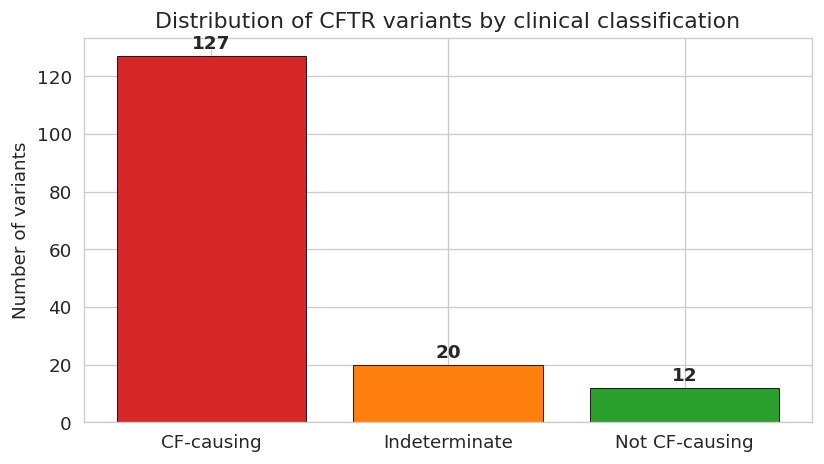


The dataset is imbalanced: 127 CF-causing vs
12 Not CF-causing vs 20 Indeterminate.


In [ ]:
# Count variants per final call category
call_counts = df_clean["final_call"].value_counts()
print("Final call distribution:")
print(call_counts)
print()

# Bar chart
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(call_counts.index, call_counts.values,
              color=[call_colours[c] for c in call_counts.index],
              edgecolor="black", linewidth=0.5)

# Add count labels on top of each bar
for bar, count in zip(bars, call_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(count), ha="center", va="bottom", fontweight="bold")

ax.set_ylabel("Number of variants")
ax.set_title("Distribution of CFTR variants by clinical classification")
plt.tight_layout()
plt.savefig("fig1_final_call_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nThe dataset is imbalanced: {call_counts['CF-causing']} CF-causing vs")
print(f"{call_counts['Not CF-causing']} Not CF-causing vs {call_counts['Indeterminate']} Indeterminate.")



### Clinical variable distributions


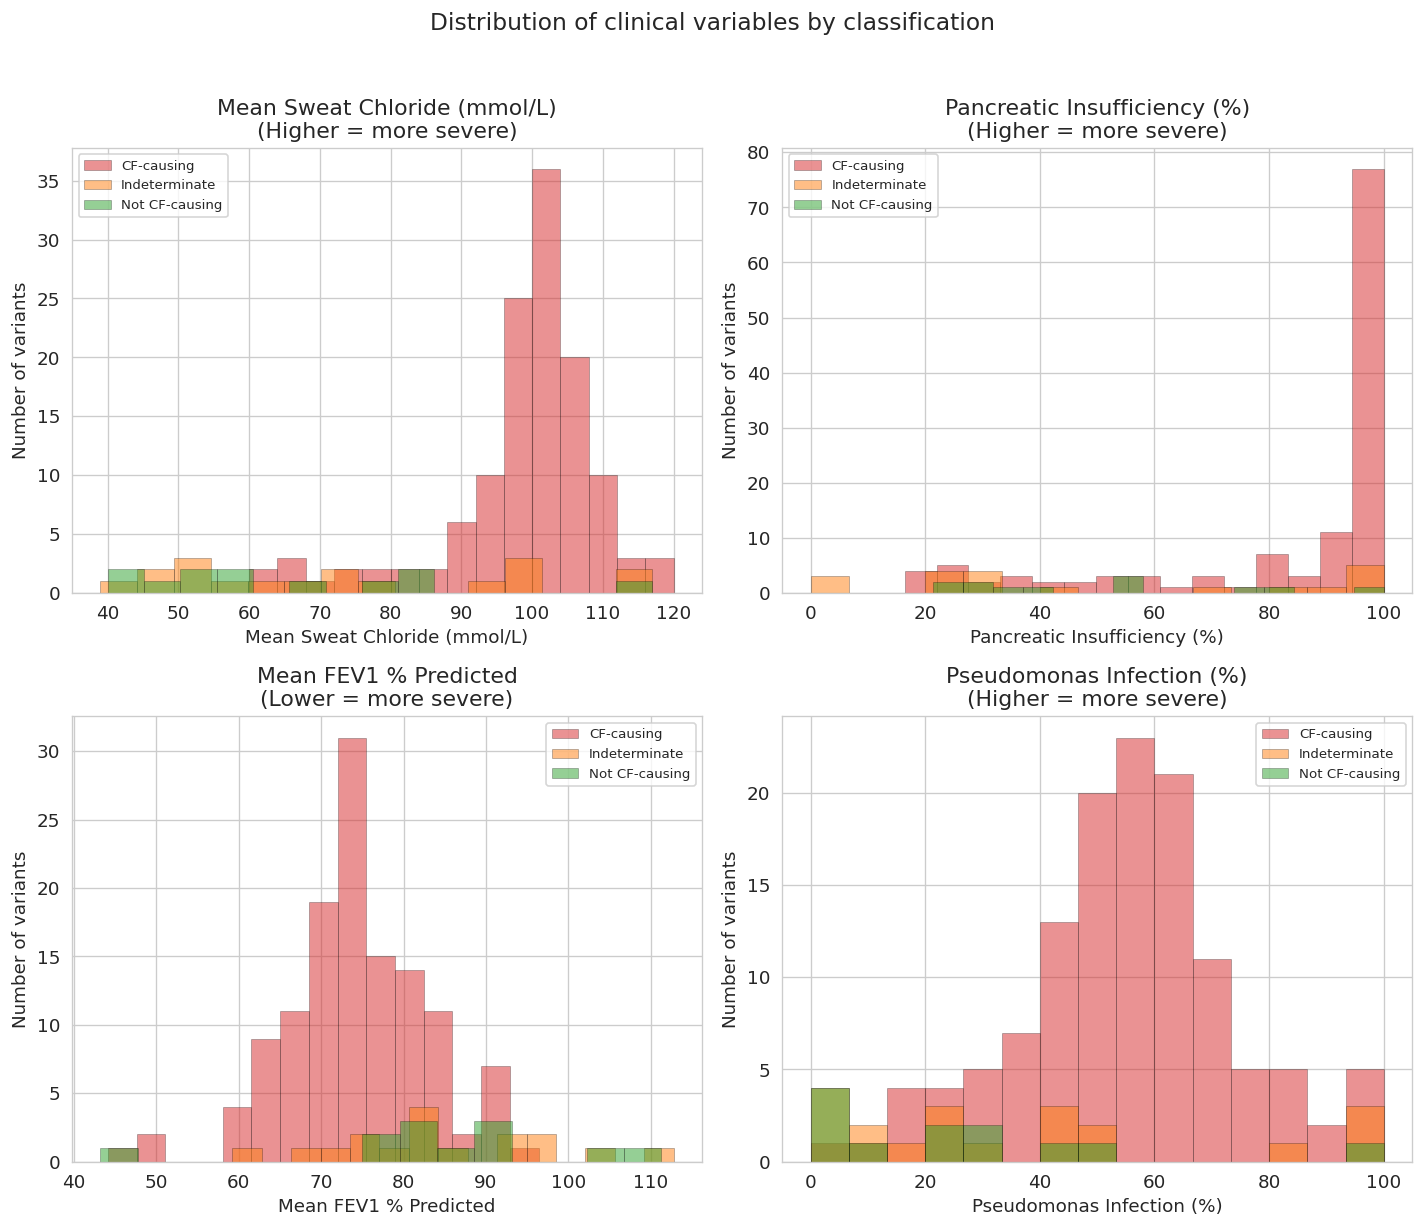

In [ ]:
# Four clinical variables to plot
clinical_vars = [
    ("mean_sweat_cl", "Mean Sweat Chloride (mmol/L)", "Higher = more severe"),
    ("pi_percent", "Pancreatic Insufficiency (%)", "Higher = more severe"),
    ("mean_fev1_pct_pred", "Mean FEV1 % Predicted", "Lower = more severe"),
    ("pseudomonas_pct", "Pseudomonas Infection (%)", "Higher = more severe"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (col, title, note) in enumerate(clinical_vars):
    ax = axes[i]

    # Plot each final call category separately so they get different colours
    for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
        subset = df_clean[df_clean["final_call"] == call_type][col].dropna()
        if len(subset) > 0:
            ax.hist(subset, bins=15, alpha=0.5, label=call_type,
                    color=call_colours[call_type], edgecolor="black", linewidth=0.3)

    ax.set_xlabel(title)
    ax.set_ylabel("Number of variants")
    ax.set_title(f"{title}\n({note})")
    ax.legend(fontsize=8)

plt.suptitle("Distribution of clinical variables by classification", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig3_clinical_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


### Boxplots by classification


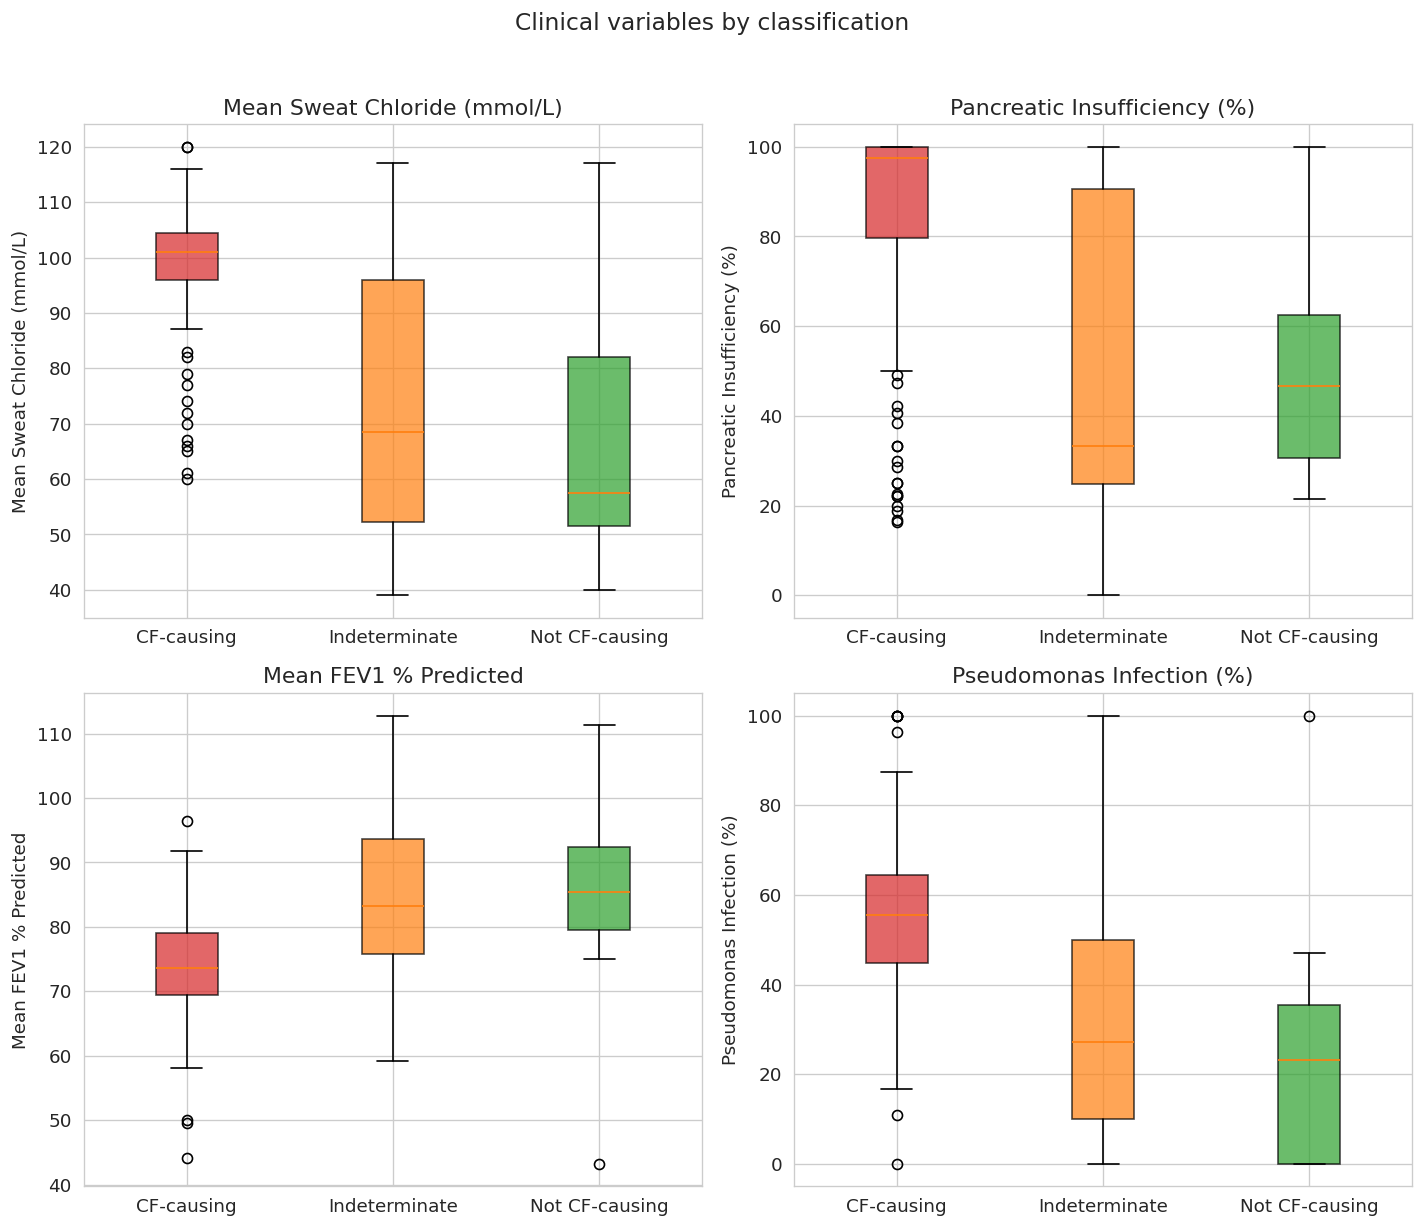

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

clinical_cols = ["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct"]
titles = ["Mean Sweat Chloride (mmol/L)", "Pancreatic Insufficiency (%)",
          "Mean FEV1 % Predicted", "Pseudomonas Infection (%)"]

order = ["CF-causing", "Indeterminate", "Not CF-causing"]

for i, (col, title) in enumerate(zip(clinical_cols, titles)):
    ax = axes[i]

    # Gather data for each category
    data_to_plot = []
    colours = []
    labels = []
    for call_type in order:
        values = df_clean[df_clean["final_call"] == call_type][col].dropna()
        if len(values) > 0:
            data_to_plot.append(values)
            colours.append(call_colours[call_type])
            labels.append(call_type)

    # Create boxplot
    bp = ax.boxplot(data_to_plot, patch_artist=True)
    ax.set_xticklabels(labels)

    # Colour each box
    for patch, colour in zip(bp["boxes"], colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.7)

    ax.set_ylabel(title)
    ax.set_title(title)

plt.suptitle("Clinical variables by classification", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig4_clinical_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()



### Summary statistics


In [ ]:
# Group by final call and compute mean and std for clinical variables
clinical_cols = ["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct"]

summary = df_clean.groupby("final_call")[clinical_cols].agg(["mean", "std", "count"])
summary = summary.round(1)

print("Summary statistics by classification:")
print("=" * 70)

for col in clinical_cols:
    print(f"\n{col}:")
    print(summary[col])


Summary statistics by classification:

mean_sweat_cl:
                mean   std  count
final_call                       
CF-causing      98.3  10.9    127
Indeterminate   72.7  24.5     18
Not CF-causing  65.8  22.5     12

pi_percent:
                mean   std  count
final_call                       
CF-causing      84.0  25.3    127
Indeterminate   50.2  37.7     20
Not CF-causing  50.6  25.2     12

mean_fev1_pct_pred:
                mean   std  count
final_call                       
CF-causing      74.1   8.6    127
Indeterminate   84.8  13.5     17
Not CF-causing  85.2  16.9     12

pseudomonas_pct:
                mean   std  count
final_call                       
CF-causing      55.0  18.5    127
Indeterminate   36.7  34.5     20
Not CF-causing  25.3  29.0     12


### Correlation heatmap


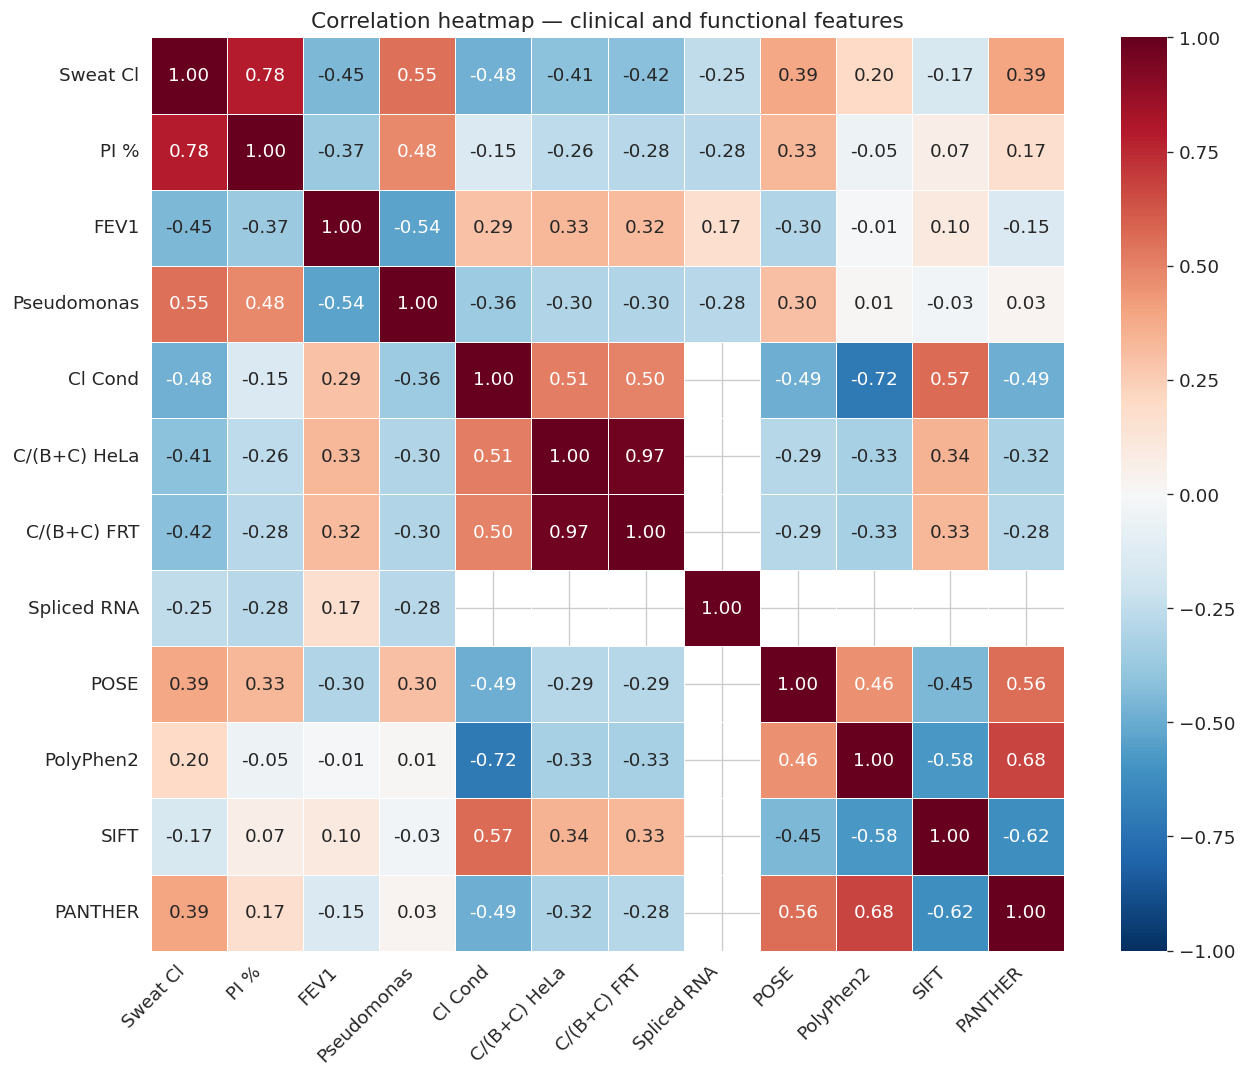

In [ ]:
# Select numeric columns for correlation
# We use both clinical targets and functional/computational features
corr_cols = [
    "mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct",
    "cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt",
    "spliced_rna_pct_wt",
    "pose_score", "polyphen2_encoded", "sift", "panther",
]

# Shorter labels for the plot
short_labels = [
    "Sweat Cl", "PI %", "FEV1", "Pseudomonas",
    "Cl Cond", "C/(B+C) HeLa", "C/(B+C) FRT",
    "Spliced RNA",
    "POSE", "PolyPhen2", "SIFT", "PANTHER",
]

# Compute correlation matrix (only using rows where both values exist)
corr_matrix = df_clean[corr_cols].corr()

# Plot
fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1,
            xticklabels=short_labels, yticklabels=short_labels,
            ax=ax, square=True, linewidths=0.5)

ax.set_title("Correlation heatmap — clinical and functional features", fontsize=13)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("fig5_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


### Functional features (missense only)


Missense variants: 65 out of 159 total



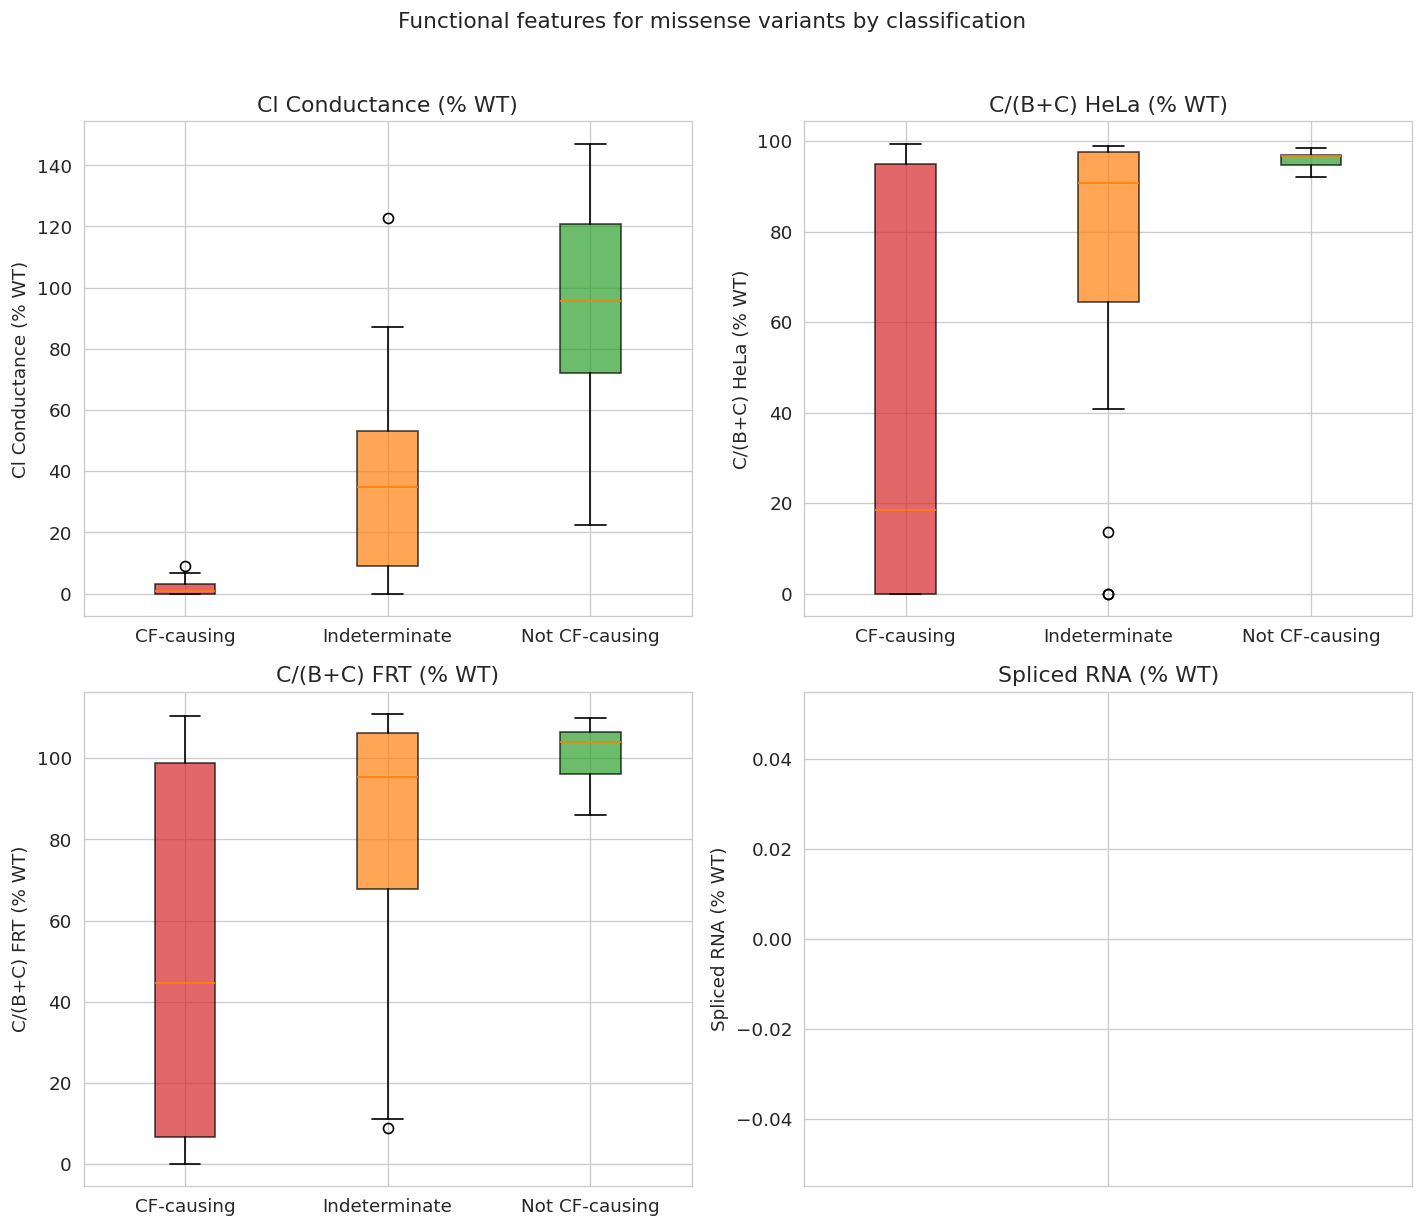

In [ ]:
# Filter to only missense variants (the ones with functional data)
missense = df_clean[df_clean["variant_type_clean"] == "missense"].copy()
print(f"Missense variants: {len(missense)} out of {len(df_clean)} total")
print()

# Boxplots of functional features, coloured by final call
func_cols = ["cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt", "spliced_rna_pct_wt"]
func_titles = ["Cl Conductance (% WT)", "C/(B+C) HeLa (% WT)",
               "C/(B+C) FRT (% WT)", "Spliced RNA (% WT)"]

order = ["CF-causing", "Indeterminate", "Not CF-causing"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (col, title) in enumerate(zip(func_cols, func_titles)):
    ax = axes[i]

    # Gather data for each category
    data_to_plot = []
    colours = []
    labels = []
    for call_type in order:
        values = missense[missense["final_call"] == call_type][col].dropna()
        if len(values) > 0:
            data_to_plot.append(values)
            colours.append(call_colours[call_type])
            labels.append(call_type)

    # Create boxplot
    bp = ax.boxplot(data_to_plot, patch_artist=True)
    ax.set_xticklabels(labels)

    # Colour each box
    for patch, colour in zip(bp["boxes"], colours):
        patch.set_facecolor(colour)
        patch.set_alpha(0.7)

    ax.set_ylabel(title)
    ax.set_title(title)

plt.suptitle("Functional features for missense variants by classification", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("fig6_functional_by_call.png", dpi=300, bbox_inches="tight")
plt.show()


### Sweat chloride vs chloride conductance


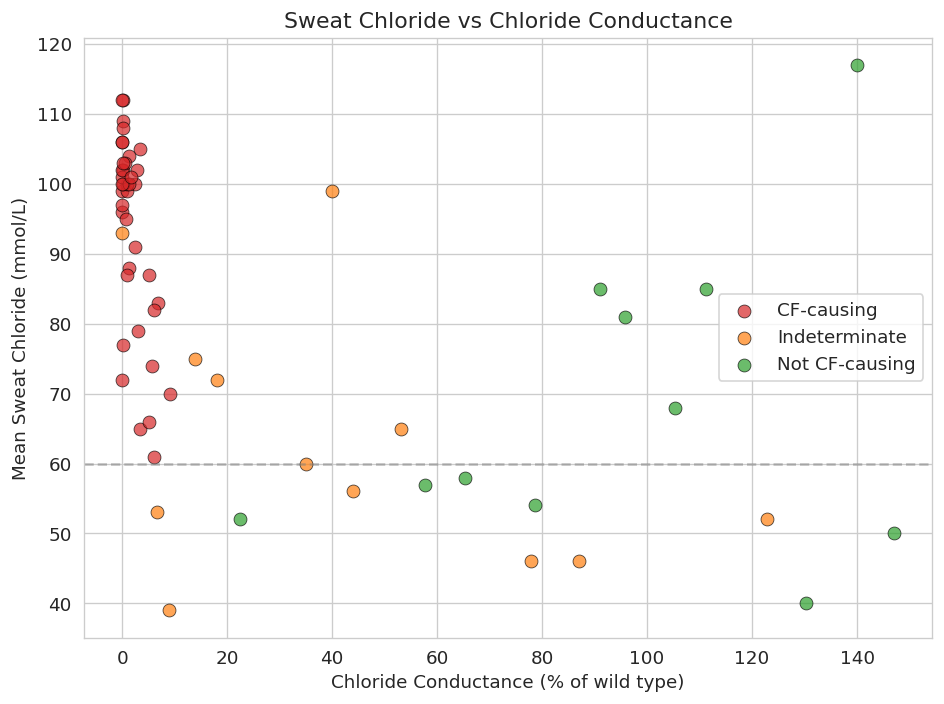

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

# Only plot variants that have both values
plot_data = df_clean.dropna(subset=["cl_conductance_pct_wt", "mean_sweat_cl"])

for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    subset = plot_data[plot_data["final_call"] == call_type]
    ax.scatter(subset["cl_conductance_pct_wt"], subset["mean_sweat_cl"],
               c=call_colours[call_type], label=call_type, s=60,
               edgecolors="black", linewidth=0.5, alpha=0.7)

ax.set_xlabel("Chloride Conductance (% of wild type)")
ax.set_ylabel("Mean Sweat Chloride (mmol/L)")
ax.set_title("Sweat Chloride vs Chloride Conductance")
ax.legend()

# Add diagnostic threshold line
ax.axhline(y=60, color="gray", linestyle="--", alpha=0.5, label="Diagnostic threshold (60 mmol/L)")

plt.tight_layout()
plt.savefig("fig7_sweat_vs_conductance.png", dpi=300, bbox_inches="tight")
plt.show()



### EDA summary


In [ ]:
print("EDA SUMMARY")
print("=" * 50)
print(f"{len(df_clean)} variants total")
print(df_clean["final_call"].value_counts().to_string())
print()
print("- Sweat Cl and PI% separate well between CF-causing and Not CF-causing")
print("- FEV1 has more overlap, Pseudomonas is noisiest")
print("- Cl conductance is the strongest functional discriminator")
print("- Functional features only available for missense (65/159)")



EDA SUMMARY
159 variants total
final_call
CF-causing        127
Indeterminate      20
Not CF-causing     12

- Sweat Cl and PI% separate well between CF-causing and Not CF-causing
- FEV1 has more overlap, Pseudomonas is noisiest
- Cl conductance is the strongest functional discriminator
- Functional features only available for missense (65/159)


---
# Unsupervised Learning
Can the data recover severity groupings without labels?


### Imports


In [ ]:
# Install umap-learn (not installed by default in Colab)
!pip install umap-learn --quiet

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import umap

print("All libraries loaded.")


All libraries loaded.


### Feature matrices
Option A = clinical features only (all 159 variants).
Option B = all features (missense only, 57-65 variants).


In [ ]:
# Option A: all variants, clinical features only
clinical_features = ["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct"]
df_clinical = df_clean.dropna(subset=clinical_features).copy()
X_clinical = df_clinical[clinical_features].values

print(f"Option A: {X_clinical.shape[0]} variants x {X_clinical.shape[1]} clinical features")
print(f"  Features: {clinical_features}")

# Option B: missense only, all features (excluding spliced RNA — no data for missense)
all_features = [
    "mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred", "pseudomonas_pct",
    "cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt",
    "pose_score", "polyphen2_encoded", "sift", "panther",
]

df_missense = df_clean[df_clean["variant_type_clean"] == "missense"].copy()
df_missense_complete = df_missense.dropna(subset=all_features).copy()
X_missense = df_missense_complete[all_features].values

print(f"\nOption B: {X_missense.shape[0]} variants x {X_missense.shape[1]} features")
print(f"  Features: {all_features}")


Option A: 156 variants x 4 clinical features
  Features: ['mean_sweat_cl', 'pi_percent', 'mean_fev1_pct_pred', 'pseudomonas_pct']

Option B: 57 variants x 11 features
  Features: ['mean_sweat_cl', 'pi_percent', 'mean_fev1_pct_pred', 'pseudomonas_pct', 'cl_conductance_pct_wt', 'cbc_hela_pct_wt', 'cbc_frt_pct_wt', 'pose_score', 'polyphen2_encoded', 'sift', 'panther']


### Standardise


In [ ]:
# Standardise Option A (clinical features, all variants)
scaler_clinical = StandardScaler()
X_clinical_scaled = scaler_clinical.fit_transform(X_clinical)

print("Option A — after standardisation:")
print(f"  Mean of each feature: {X_clinical_scaled.mean(axis=0).round(4)}")
print(f"  Std of each feature:  {X_clinical_scaled.std(axis=0).round(4)}")
print()

# Standardise Option B (all features, missense only)
scaler_missense = StandardScaler()
X_missense_scaled = scaler_missense.fit_transform(X_missense)

print("Option B — after standardisation:")
print(f"  Mean of each feature: {X_missense_scaled.mean(axis=0).round(4)}")
print(f"  Std of each feature:  {X_missense_scaled.std(axis=0).round(4)}")


Option A — after standardisation:
  Mean of each feature: [-0. -0.  0.  0.]
  Std of each feature:  [1. 1. 1. 1.]

Option B — after standardisation:
  Mean of each feature: [ 0. -0.  0.  0. -0.  0.  0. -0. -0. -0.  0.]
  Std of each feature:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### PCA


In [ ]:
# --- PCA on Option A (all variants, clinical features) ---
pca_clinical = PCA()
X_clinical_pca = pca_clinical.fit_transform(X_clinical_scaled)

print("Option A — PCA explained variance:")
for i, var in enumerate(pca_clinical.explained_variance_ratio_):
    cumulative = sum(pca_clinical.explained_variance_ratio_[:i+1])
    print(f"  PC{i+1}: {var:.1%} (cumulative: {cumulative:.1%})")

print()

# --- PCA on Option B (missense, all features) ---
pca_missense = PCA()
X_missense_pca = pca_missense.fit_transform(X_missense_scaled)

print("Option B — PCA explained variance (top 6):")
for i, var in enumerate(pca_missense.explained_variance_ratio_[:6]):
    cumulative = sum(pca_missense.explained_variance_ratio_[:i+1])
    print(f"  PC{i+1}: {var:.1%} (cumulative: {cumulative:.1%})")


Option A — PCA explained variance:
  PC1: 65.3% (cumulative: 65.3%)
  PC2: 18.6% (cumulative: 83.9%)
  PC3: 11.0% (cumulative: 94.9%)
  PC4: 5.1% (cumulative: 100.0%)

Option B — PCA explained variance (top 6):
  PC1: 45.9% (cumulative: 45.9%)
  PC2: 18.2% (cumulative: 64.1%)
  PC3: 10.6% (cumulative: 74.7%)
  PC4: 8.1% (cumulative: 82.8%)
  PC5: 5.2% (cumulative: 88.0%)
  PC6: 3.6% (cumulative: 91.6%)


### PCA scatter plots


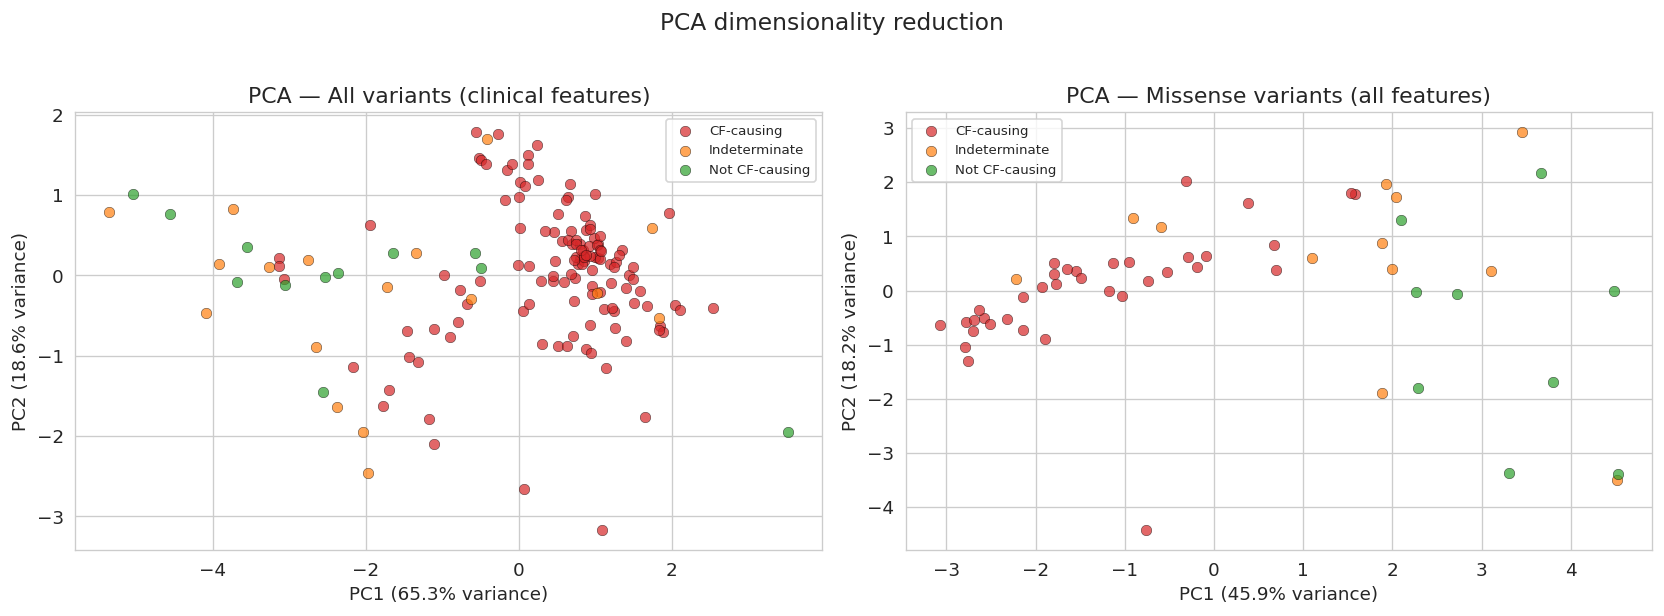

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Option A: All variants, clinical features ---
ax = axes[0]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_clinical["final_call"].values == call_type
    ax.scatter(X_clinical_pca[mask, 0], X_clinical_pca[mask, 1],
               c=call_colours[call_type], label=call_type, s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)

var1 = pca_clinical.explained_variance_ratio_[0]
var2 = pca_clinical.explained_variance_ratio_[1]
ax.set_xlabel(f"PC1 ({var1:.1%} variance)")
ax.set_ylabel(f"PC2 ({var2:.1%} variance)")
ax.set_title("PCA — All variants (clinical features)")
ax.legend(fontsize=8)

# --- Option B: Missense, all features ---
ax = axes[1]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_missense_complete["final_call"].values == call_type
    if mask.sum() > 0:
        ax.scatter(X_missense_pca[mask, 0], X_missense_pca[mask, 1],
                   c=call_colours[call_type], label=call_type, s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)

var1 = pca_missense.explained_variance_ratio_[0]
var2 = pca_missense.explained_variance_ratio_[1]
ax.set_xlabel(f"PC1 ({var1:.1%} variance)")
ax.set_ylabel(f"PC2 ({var2:.1%} variance)")
ax.set_title("PCA — Missense variants (all features)")
ax.legend(fontsize=8)

plt.suptitle("PCA dimensionality reduction", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig8_pca_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


### PCA loadings


In [ ]:
# Option A loadings
print("Option A — What drives each principal component:")
print("=" * 55)
for i in range(min(3, len(clinical_features))):
    print(f"\nPC{i+1} ({pca_clinical.explained_variance_ratio_[i]:.1%} variance):")
    loadings = pca_clinical.components_[i]
    # Sort by absolute value
    sorted_idx = abs(loadings).argsort()[::-1]
    for idx in sorted_idx:
        print(f"  {clinical_features[idx]:<25} {loadings[idx]:+.3f}")

print()
print("Option B — What drives each principal component (top 3):")
print("=" * 55)
for i in range(3):
    print(f"\nPC{i+1} ({pca_missense.explained_variance_ratio_[i]:.1%} variance):")
    loadings = pca_missense.components_[i]
    sorted_idx = abs(loadings).argsort()[::-1]
    for idx in sorted_idx[:5]:  # show top 5 features
        print(f"  {all_features[idx]:<25} {loadings[idx]:+.3f}")


Option A — What drives each principal component:

PC1 (65.3% variance):
  mean_sweat_cl             +0.549
  pi_percent                +0.513
  pseudomonas_pct           +0.496
  mean_fev1_pct_pred        -0.435

PC2 (18.6% variance):
  mean_fev1_pct_pred        +0.703
  pi_percent                +0.525
  mean_sweat_cl             +0.355
  pseudomonas_pct           -0.321

PC3 (11.0% variance):
  pseudomonas_pct           +0.794
  mean_fev1_pct_pred        +0.562
  pi_percent                -0.225
  mean_sweat_cl             -0.062

Option B — What drives each principal component (top 3):

PC1 (45.9% variance):
  cl_conductance_pct_wt     +0.368
  mean_sweat_cl             -0.340
  cbc_hela_pct_wt           +0.323
  cbc_frt_pct_wt            +0.321
  pose_score                -0.301

PC2 (18.2% variance):
  polyphen2_encoded         +0.468
  sift                      -0.402
  pi_percent                -0.380
  panther                   +0.375
  pseudomonas_pct           -0.357

PC3 (10

### UMAP


/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


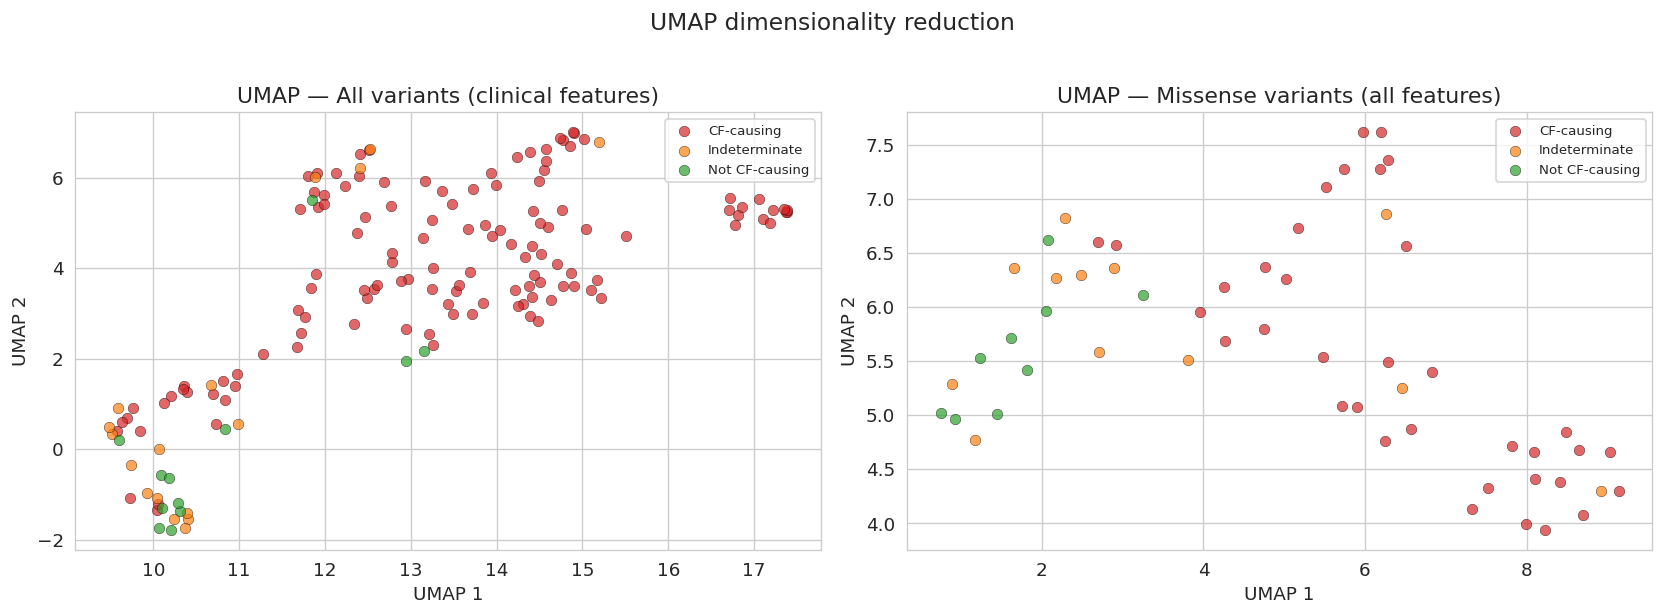

In [ ]:
# --- UMAP on Option A (all variants, clinical features) ---
reducer_clinical = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_clinical_umap = reducer_clinical.fit_transform(X_clinical_scaled)

# --- UMAP on Option B (missense, all features) ---
reducer_missense = umap.UMAP(n_neighbors=10, min_dist=0.1, random_state=42)
X_missense_umap = reducer_missense.fit_transform(X_missense_scaled)

# Plot both
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Option A
ax = axes[0]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_clinical["final_call"].values == call_type
    ax.scatter(X_clinical_umap[mask, 0], X_clinical_umap[mask, 1],
               c=call_colours[call_type], label=call_type, s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP — All variants (clinical features)")
ax.legend(fontsize=8)

# Option B
ax = axes[1]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_missense_complete["final_call"].values == call_type
    if mask.sum() > 0:
        ax.scatter(X_missense_umap[mask, 0], X_missense_umap[mask, 1],
                   c=call_colours[call_type], label=call_type, s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP — Missense variants (all features)")
ax.legend(fontsize=8)

plt.suptitle("UMAP dimensionality reduction", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig9_umap_scatter.png", dpi=300, bbox_inches="tight")
plt.show()



### K-means — optimal k


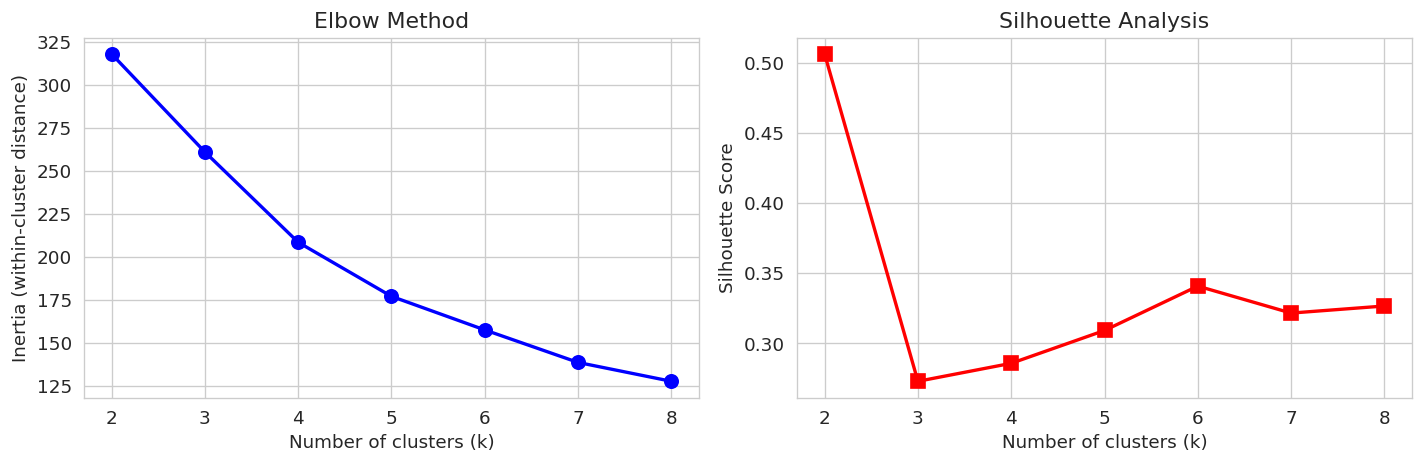

K-means evaluation:
  k=2: inertia=317.8, silhouette=0.506
  k=3: inertia=260.9, silhouette=0.273
  k=4: inertia=208.4, silhouette=0.286
  k=5: inertia=177.0, silhouette=0.309
  k=6: inertia=157.5, silhouette=0.341
  k=7: inertia=138.6, silhouette=0.321
  k=8: inertia=127.7, silhouette=0.327

Best k by silhouette score: 2


In [ ]:
# Test k=2 to k=8 on Option A (all variants, clinical features)
k_range = range(2, 9)
inertias = []
silhouettes = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_clinical_scaled)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_clinical_scaled, cluster_labels))

# Plot elbow and silhouette
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Elbow plot
ax = axes[0]
ax.plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia (within-cluster distance)")
ax.set_title("Elbow Method")

# Silhouette plot
ax = axes[1]
ax.plot(k_range, silhouettes, 'rs-', linewidth=2, markersize=8)
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Silhouette Analysis")

plt.tight_layout()
plt.savefig("fig10_kmeans_evaluation.png", dpi=300, bbox_inches="tight")
plt.show()

# Print scores
print("K-means evaluation:")
for k, inertia, sil in zip(k_range, inertias, silhouettes):
    print(f"  k={k}: inertia={inertia:.1f}, silhouette={sil:.3f}")

best_k = list(k_range)[silhouettes.index(max(silhouettes))]
print(f"\nBest k by silhouette score: {best_k}")


### Apply K-means


In [ ]:
# Apply K-means with best k (we'll also try k=3 since we know there are 3 categories)
for k in [best_k, 3]:
    print(f"\n{'='*50}")
    print(f"K-MEANS WITH k={k}")
    print(f"{'='*50}")

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    df_clinical[f"cluster_k{k}"] = kmeans.fit_predict(X_clinical_scaled)

    # Cluster sizes
    print(f"\nCluster sizes:")
    print(df_clinical[f"cluster_k{k}"].value_counts().sort_index())

    # Cluster profiles — mean clinical values per cluster
    print(f"\nCluster profiles (mean clinical values):")
    profile = df_clinical.groupby(f"cluster_k{k}")[clinical_features].mean().round(1)
    print(profile)

    # How well do clusters match final call?
    print(f"\nCluster vs Final Call (crosstab):")
    ct = pd.crosstab(df_clinical[f"cluster_k{k}"], df_clinical["final_call"])
    print(ct)



K-MEANS WITH k=2

Cluster sizes:
cluster_k2
0    119
1     37
Name: count, dtype: int64

Cluster profiles (mean clinical values):
            mean_sweat_cl  pi_percent  mean_fev1_pct_pred  pseudomonas_pct
cluster_k2                                                                
0                   101.2        91.5                73.3             57.8
1                    65.5        32.3                85.1             28.2

Cluster vs Final Call (crosstab):
final_call  CF-causing  Indeterminate  Not CF-causing
cluster_k2                                           
0                  111              5               3
1                   16             12               9

K-MEANS WITH k=3

Cluster sizes:
cluster_k3
0    43
1    35
2    78
Name: count, dtype: int64

Cluster profiles (mean clinical values):
            mean_sweat_cl  pi_percent  mean_fev1_pct_pred  pseudomonas_pct
cluster_k3                                                                
0                   101.4      

### Clusters vs known labels


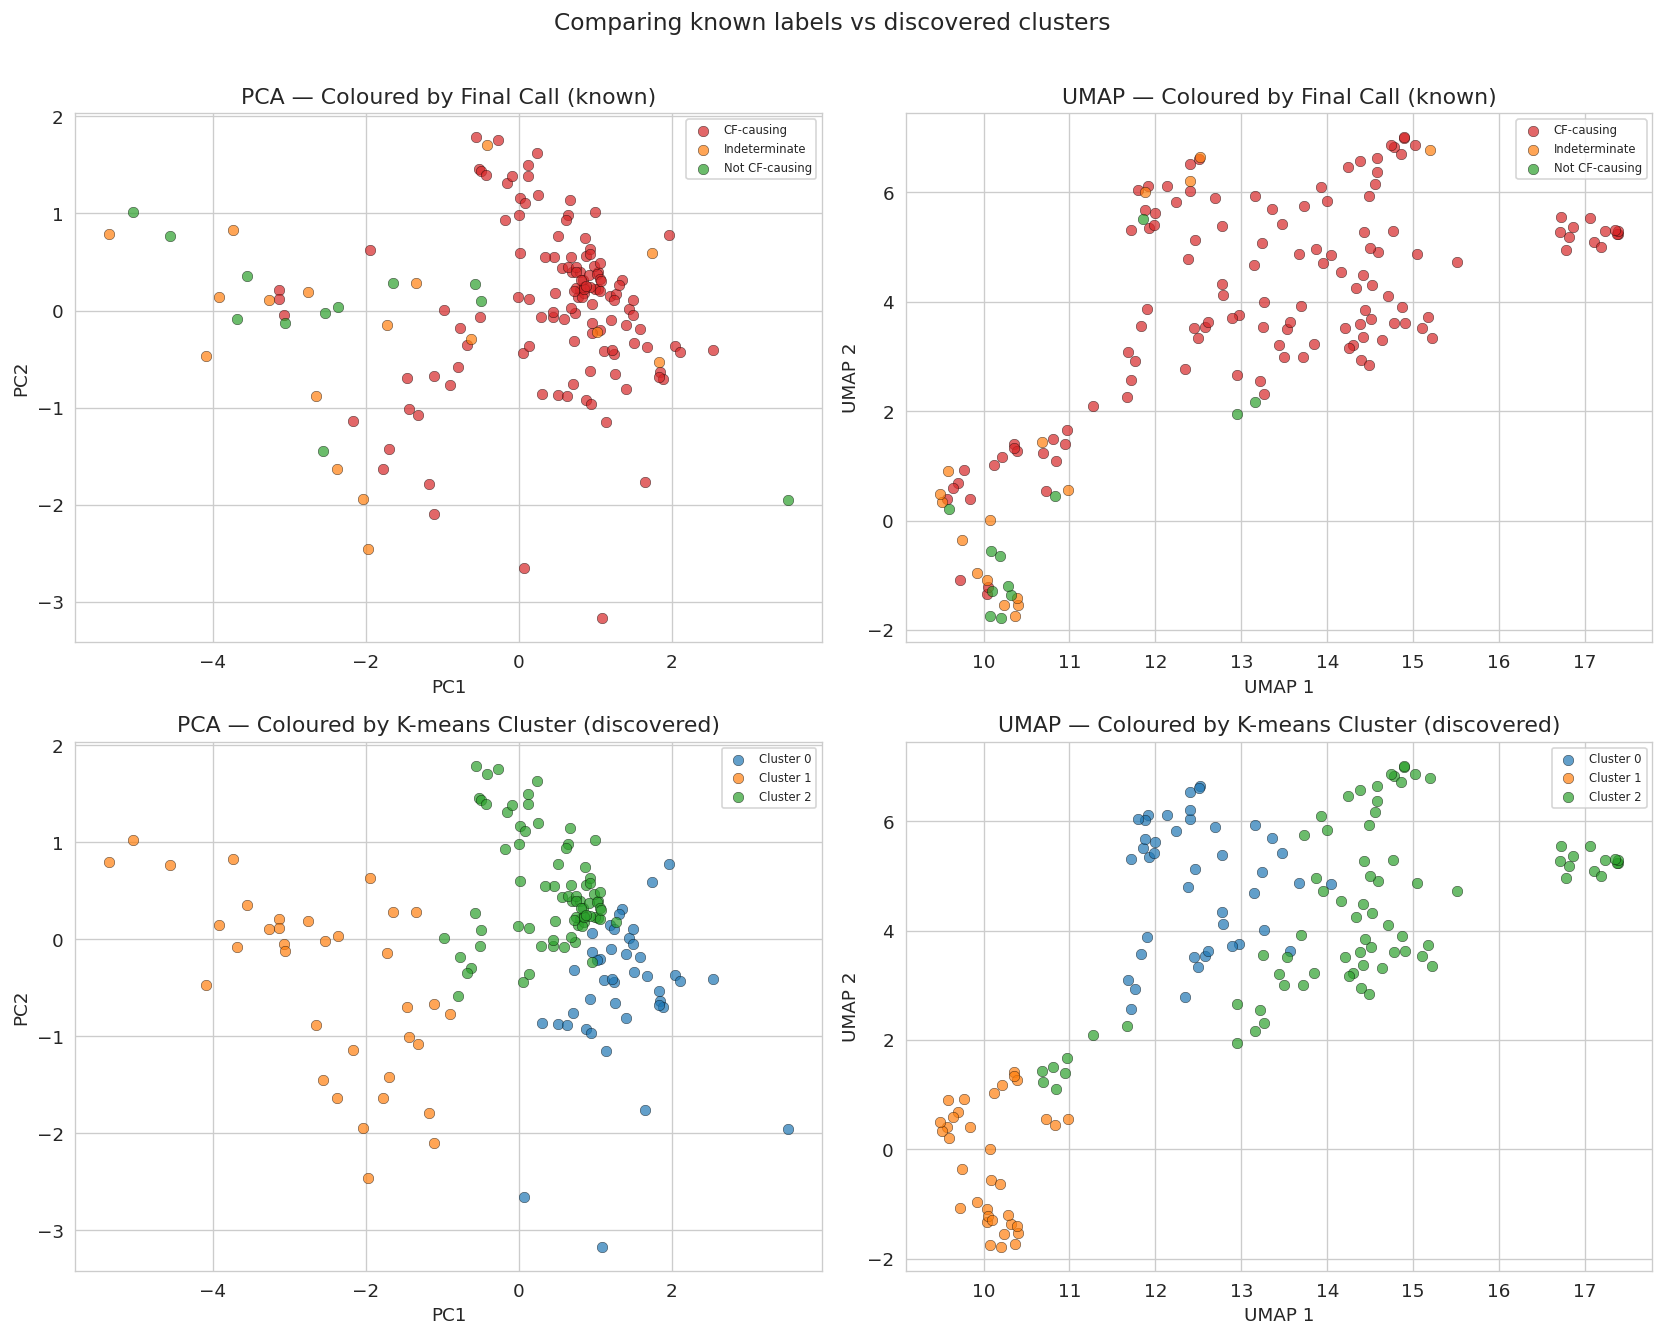

In [ ]:
# Use k=3 for this visualisation (matches the 3 known categories)
cluster_col = "cluster_k3" if "cluster_k3" in df_clinical.columns else f"cluster_k{best_k}"
n_clusters = df_clinical[cluster_col].nunique()

# Cluster colour palette
cluster_palette = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c", 3: "#d62728",
                   4: "#9467bd", 5: "#8c564b", 6: "#e377c2", 7: "#7f7f7f"}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# Row 1: Coloured by FINAL CALL (what we know)
ax = axes[0][0]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_clinical["final_call"].values == call_type
    ax.scatter(X_clinical_pca[mask, 0], X_clinical_pca[mask, 1],
               c=call_colours[call_type], label=call_type, s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA — Coloured by Final Call (known)")
ax.legend(fontsize=7)

ax = axes[0][1]
for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
    mask = df_clinical["final_call"].values == call_type
    ax.scatter(X_clinical_umap[mask, 0], X_clinical_umap[mask, 1],
               c=call_colours[call_type], label=call_type, s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP — Coloured by Final Call (known)")
ax.legend(fontsize=7)

# Row 2: Coloured by CLUSTER (what the algorithm found)
ax = axes[1][0]
for c in range(n_clusters):
    mask = df_clinical[cluster_col].values == c
    ax.scatter(X_clinical_pca[mask, 0], X_clinical_pca[mask, 1],
               c=cluster_palette[c], label=f"Cluster {c}", s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA — Coloured by K-means Cluster (discovered)")
ax.legend(fontsize=7)

ax = axes[1][1]
for c in range(n_clusters):
    mask = df_clinical[cluster_col].values == c
    ax.scatter(X_clinical_umap[mask, 0], X_clinical_umap[mask, 1],
               c=cluster_palette[c], label=f"Cluster {c}", s=40,
               edgecolors="black", linewidth=0.3, alpha=0.7)
ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP — Coloured by K-means Cluster (discovered)")
ax.legend(fontsize=7)

plt.suptitle("Comparing known labels vs discovered clusters", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("fig11_clusters_vs_labels.png", dpi=300, bbox_inches="tight")
plt.show()


### Hierarchical clustering


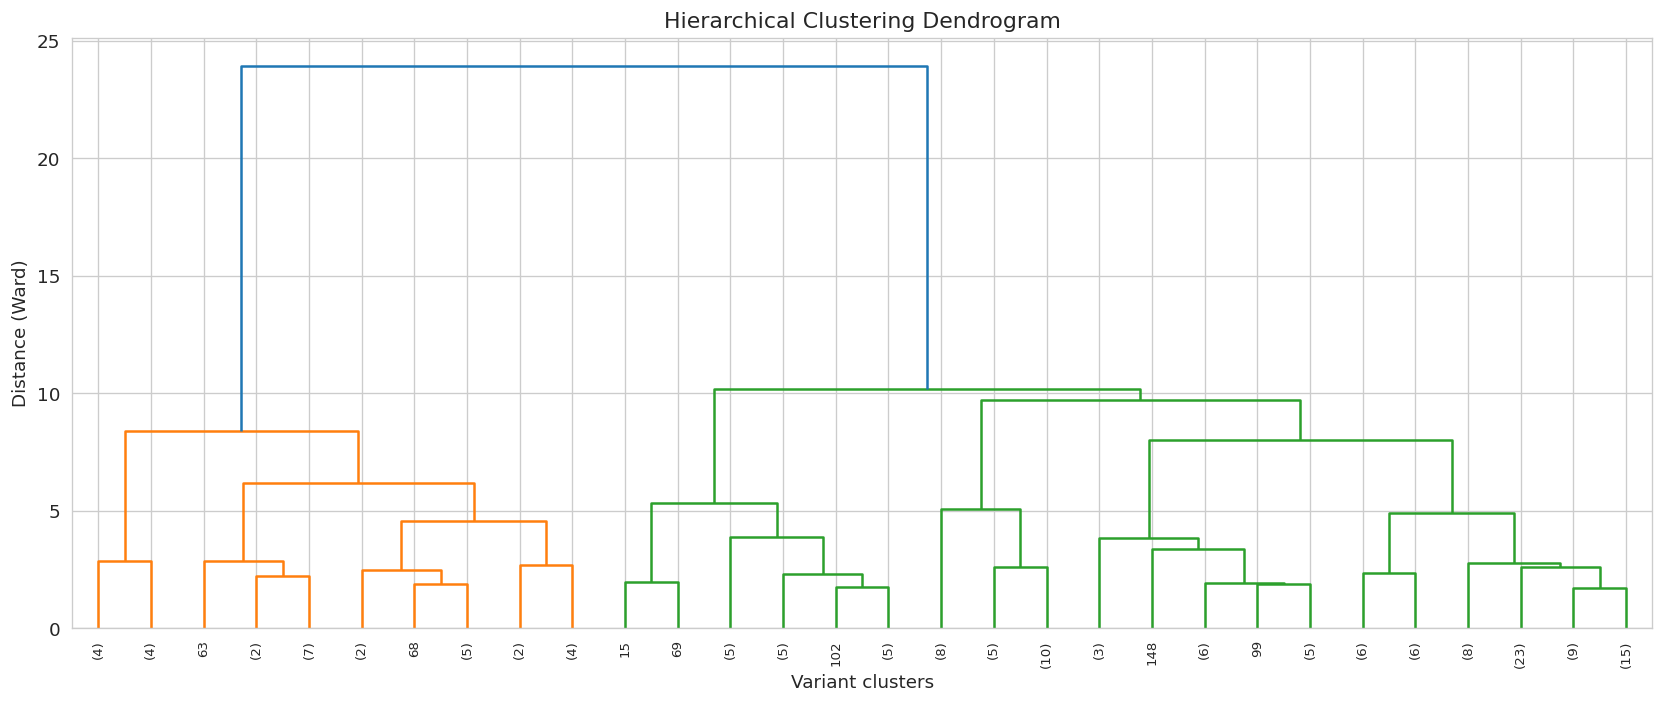

In [ ]:
# Compute linkage matrix using Ward's method
# Ward's method minimises the total within-cluster variance (same idea as K-means)
linkage_matrix = linkage(X_clinical_scaled, method="ward")

# Plot dendrogram
fig, ax = plt.subplots(figsize=(14, 6))

# Use final call as labels, truncate to show top structure
dendrogram(linkage_matrix, ax=ax, truncate_mode="lastp", p=30,
           leaf_rotation=90, leaf_font_size=8)

ax.set_xlabel("Variant clusters")
ax.set_ylabel("Distance (Ward)")
ax.set_title("Hierarchical Clustering Dendrogram")

plt.tight_layout()
plt.savefig("fig12_dendrogram.png", dpi=300, bbox_inches="tight")
plt.show()



### Unsupervised summary


In [ ]:
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(X_clinical_scaled)
sil_final = silhouette_score(X_clinical_scaled, labels_final)

print("UNSUPERVISED LEARNING SUMMARY")
print("=" * 50)
print(f"PCA: PC1+PC2 explain {sum(pca_clinical.explained_variance_ratio_[:2]):.1%} of variance")
print(f"Best k by silhouette: {best_k}")
print(f"Silhouette score (k=3): {sil_final:.3f}")
print()
ct_final = pd.crosstab(df_clinical["cluster_k3"], df_clinical["final_call"])
print("Cluster vs Final Call:")
print(ct_final)
print()
print("Clusters partially recover the known classification.")



UNSUPERVISED LEARNING SUMMARY
PCA: PC1+PC2 explain 83.9% of variance
Best k by silhouette: 2
Silhouette score (k=3): 0.273

Cluster vs Final Call:
final_call  CF-causing  Indeterminate  Not CF-causing
cluster_k3                                           
0                   39              3               1
1                   14             12               9
2                   74              2               2

Clusters partially recover the known classification.


---
# Supervised Learning — Per-Allele Prediction
Predict sweat Cl, FEV1, PI% from functional/computational features using Random Forest.


### Imports


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_predict, cross_val_score, LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings("ignore")

print("Supervised learning libraries loaded.")


Supervised learning libraries loaded.


### Features and targets
Using all 159 variants. Missing functional data for non-missense variants
gets median-imputed — the one-hot variant type columns already tell the model
what kind of mutation it is.


In [ ]:
# Define features (what we use to predict)
feature_cols = [
    # Variant type (one-hot) — available for all variants
    "vtype_canonical_splice", "vtype_frameshift", "vtype_inframe_indel",
    "vtype_missense", "vtype_nonsense", "vtype_splice_other",
    # Functional features — only available for missense
    "cl_conductance_pct_wt", "cbc_hela_pct_wt", "cbc_frt_pct_wt",
    # Computational predictions — only available for missense
    "pose_score", "polyphen2_encoded", "sift", "panther",
]

# Check which feature columns actually exist in df_clean
# (one-hot column names might differ between pandas versions)
available_features = [col for col in feature_cols if col in df_clean.columns]
missing_features = [col for col in feature_cols if col not in df_clean.columns]

if missing_features:
    print(f"Warning: these columns not found: {missing_features}")
    # Try to find vtype columns dynamically
    vtype_cols = [c for c in df_clean.columns if c.startswith("vtype_")]
    other_features = [c for c in feature_cols if not c.startswith("vtype_")]
    available_features = vtype_cols + [c for c in other_features if c in df_clean.columns]

print(f"Features ({len(available_features)}):")
for f in available_features:
    n_valid = df_clean[f].notna().sum()
    print(f"  {f:<30} {n_valid}/{len(df_clean)} non-null")

# Define targets (what we predict)
target_cols = ["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred"]
print(f"\nTargets ({len(target_cols)}):")
for t in target_cols:
    n_valid = df_clean[t].notna().sum()
    print(f"  {t:<30} {n_valid}/{len(df_clean)} non-null")


Features (13):
  vtype_canonical_splice         159/159 non-null
  vtype_frameshift               159/159 non-null
  vtype_inframe_indel            159/159 non-null
  vtype_missense                 159/159 non-null
  vtype_nonsense                 159/159 non-null
  vtype_splice_other             159/159 non-null
  cl_conductance_pct_wt          63/159 non-null
  cbc_hela_pct_wt                67/159 non-null
  cbc_frt_pct_wt                 63/159 non-null
  pose_score                     64/159 non-null
  polyphen2_encoded              64/159 non-null
  sift                           63/159 non-null
  panther                        62/159 non-null

Targets (3):
  mean_sweat_cl                  157/159 non-null
  pi_percent                     159/159 non-null
  mean_fev1_pct_pred             156/159 non-null


### Imputation & matrix setup


In [ ]:
# Start with the feature matrix
X_raw = df_clean[available_features].copy()

# Impute missing values with median
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X_raw),
    columns=available_features,
    index=df_clean.index
)

# Check imputation worked
print("After imputation — missing values per feature:")
print(X_imputed.isnull().sum().sum(), "total missing (should be 0)")
print()

# Build target matrix
y_raw = df_clean[target_cols].copy()

# Find rows where ALL targets are available
complete_mask = y_raw.notna().all(axis=1)
print(f"Variants with all 3 targets available: {complete_mask.sum()} out of {len(df_clean)}")

# Final feature and target matrices
X = X_imputed.loc[complete_mask].values
y = y_raw.loc[complete_mask].values

# Also keep the labels and names for later plotting
labels_for_plot = df_clean.loc[complete_mask, "final_call"].values
names_for_plot = df_clean.loc[complete_mask, "variant_legacy"].values

print(f"\nFinal matrices:")
print(f"  X (features): {X.shape}")
print(f"  y (targets):  {y.shape}")
print(f"  y columns: {target_cols}")


After imputation — missing values per feature:
0 total missing (should be 0)

Variants with all 3 targets available: 156 out of 159

Final matrices:
  X (features): (156, 13)
  y (targets):  (156, 3)
  y columns: ['mean_sweat_cl', 'pi_percent', 'mean_fev1_pct_pred']


### Random Forest with LOOCV
~156 usable variants, so LOOCV makes the most of the data.
One model per target.


In [ ]:
# We train one model per target
results = {}

for i, target_name in enumerate(target_cols):
    print(f"\n{'='*50}")
    print(f"Training model for: {target_name}")
    print(f"{'='*50}")

    y_single = y[:, i]

    # Random Forest Regressor
    rf = RandomForestRegressor(
        n_estimators=500,       # number of trees
        max_depth=None,         # let trees grow fully
        min_samples_split=5,    # need at least 5 samples to split
        min_samples_leaf=2,     # each leaf has at least 2 samples
        random_state=42,
        n_jobs=-1               # use all CPU cores
    )

    # Leave-One-Out cross-validation predictions
    loo = LeaveOneOut()
    y_pred = cross_val_predict(rf, X, y_single, cv=loo)

    # Calculate metrics
    r2 = r2_score(y_single, y_pred)
    rmse = np.sqrt(mean_squared_error(y_single, y_pred))
    mae = mean_absolute_error(y_single, y_pred)

    results[target_name] = {
        "y_true": y_single,
        "y_pred": y_pred,
        "r2": r2,
        "rmse": rmse,
        "mae": mae,
    }

    print(f"  R² score:  {r2:.3f}")
    print(f"  RMSE:      {rmse:.1f}")
    print(f"  MAE:       {mae:.1f}")
    print(f"  (higher R² = better, lower RMSE/MAE = better)")

print(f"\n\nSUMMARY:")
print(f"{'Target':<25} {'R²':>6} {'RMSE':>8} {'MAE':>8}")
print("-" * 50)
for name, res in results.items():
    print(f"{name:<25} {res['r2']:>6.3f} {res['rmse']:>8.1f} {res['mae']:>8.1f}")



Training model for: mean_sweat_cl
  R² score:  0.506
  RMSE:      12.6
  MAE:       8.7
  (higher R² = better, lower RMSE/MAE = better)

Training model for: pi_percent
  R² score:  0.545
  RMSE:      19.9
  MAE:       13.1
  (higher R² = better, lower RMSE/MAE = better)

Training model for: mean_fev1_pct_pred
  R² score:  -0.037
  RMSE:      11.0
  MAE:       8.1
  (higher R² = better, lower RMSE/MAE = better)


SUMMARY:
Target                        R²     RMSE      MAE
--------------------------------------------------
mean_sweat_cl              0.506     12.6      8.7
pi_percent                 0.545     19.9     13.1
mean_fev1_pct_pred        -0.037     11.0      8.1


### Predicted vs actual


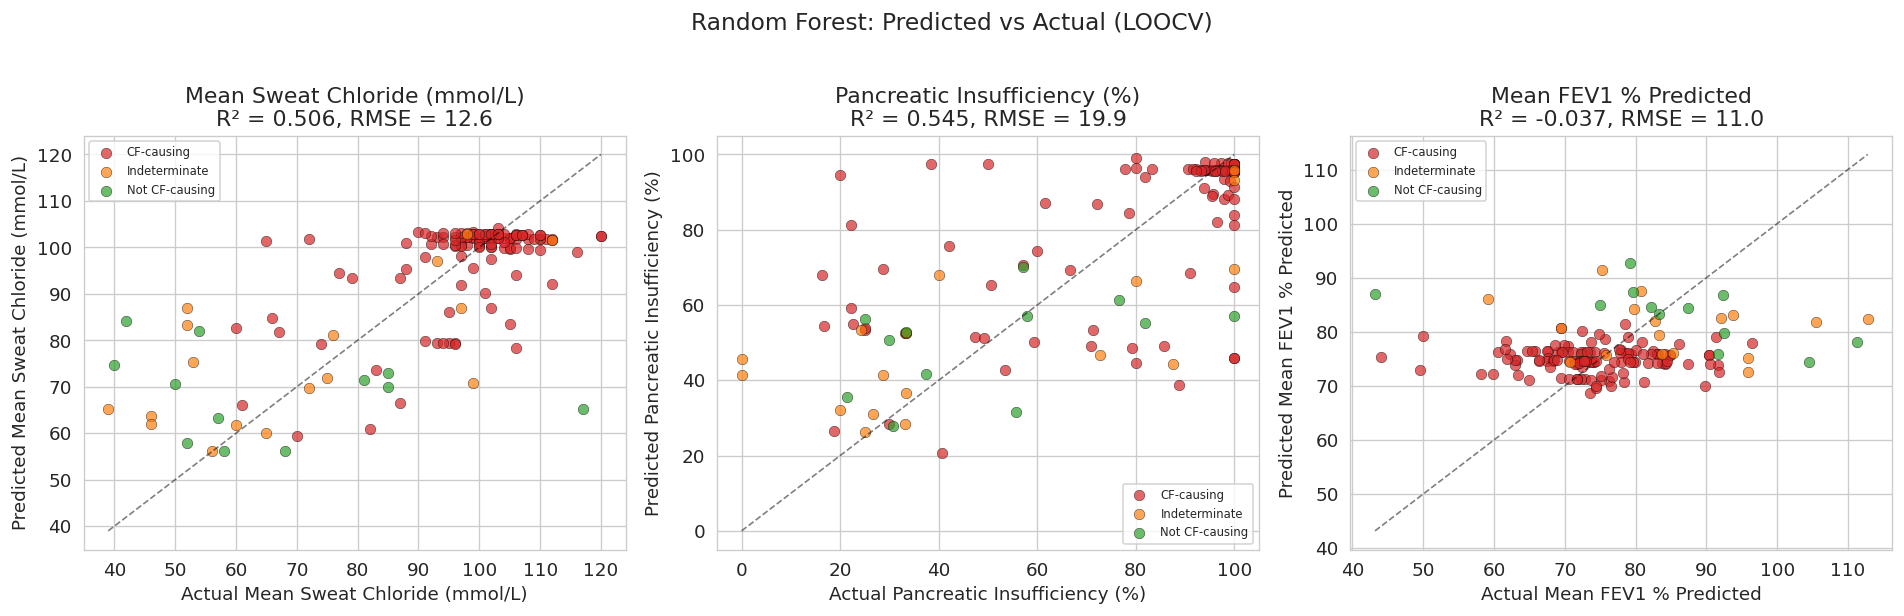

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

titles = ["Mean Sweat Chloride (mmol/L)", "Pancreatic Insufficiency (%)",
          "Mean FEV1 % Predicted"]

for i, (target_name, title) in enumerate(zip(target_cols, titles)):
    ax = axes[i]
    res = results[target_name]

    # Plot each category with different colours
    for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
        mask = labels_for_plot == call_type
        ax.scatter(res["y_true"][mask], res["y_pred"][mask],
                   c=call_colours[call_type], label=call_type, s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)

    # Perfect prediction line
    min_val = min(res["y_true"].min(), res["y_pred"].min())
    max_val = max(res["y_true"].max(), res["y_pred"].max())
    ax.plot([min_val, max_val], [min_val, max_val], "k--", alpha=0.5, linewidth=1)

    ax.set_xlabel(f"Actual {title}")
    ax.set_ylabel(f"Predicted {title}")
    ax.set_title(f"{title}\nR² = {res['r2']:.3f}, RMSE = {res['rmse']:.1f}")
    ax.legend(fontsize=7)

plt.suptitle("Random Forest: Predicted vs Actual (LOOCV)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig13_predicted_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


### Feature importance (permutation)


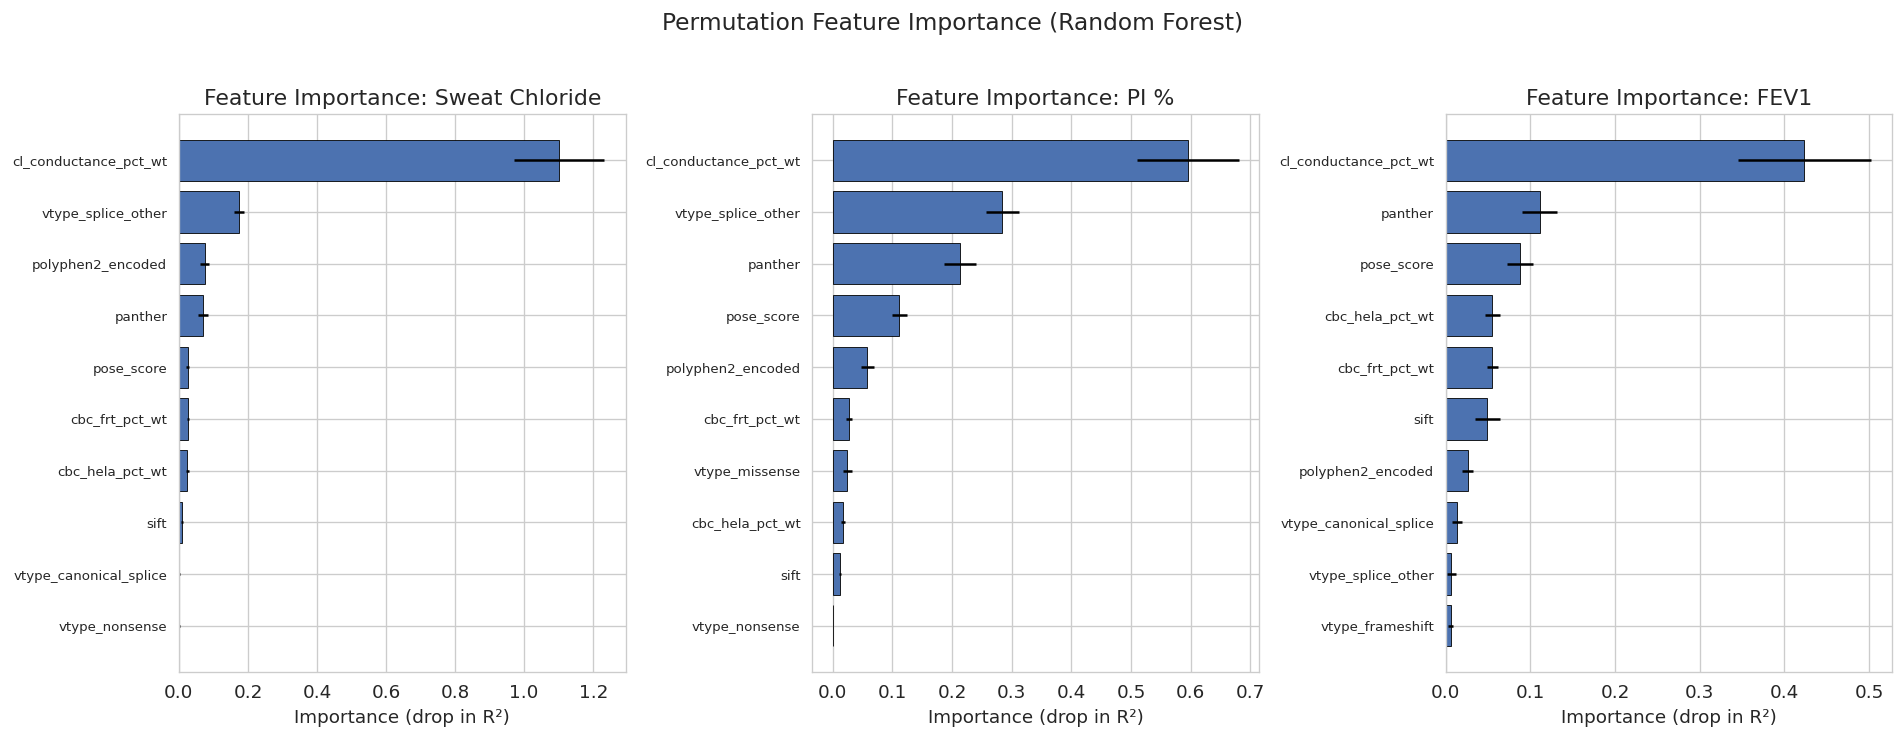

In [ ]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

titles = ["Sweat Chloride", "PI %", "FEV1"]

for i, (target_name, title) in enumerate(zip(target_cols, titles)):
    ax = axes[i]
    y_single = y[:, i]

    # Train on ALL data for feature importance (we already have LOOCV for evaluation)
    rf = RandomForestRegressor(
        n_estimators=500, max_depth=None, min_samples_split=5,
        min_samples_leaf=2, random_state=42, n_jobs=-1
    )
    rf.fit(X, y_single)

    # Permutation importance
    perm_imp = permutation_importance(rf, X, y_single, n_repeats=20, random_state=42)

    # Sort by importance
    sorted_idx = perm_imp.importances_mean.argsort()[::-1]

    # Plot top 10
    top_n = min(10, len(available_features))
    top_idx = sorted_idx[:top_n]

    ax.barh(range(top_n),
            perm_imp.importances_mean[top_idx],
            xerr=perm_imp.importances_std[top_idx],
            color="#4C72B0", edgecolor="black", linewidth=0.5)

    ax.set_yticks(range(top_n))
    ax.set_yticklabels([available_features[j] for j in top_idx], fontsize=8)
    ax.set_xlabel("Importance (drop in R²)")
    ax.set_title(f"Feature Importance: {title}")
    ax.invert_yaxis()

plt.suptitle("Permutation Feature Importance (Random Forest)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig14_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


### Residuals


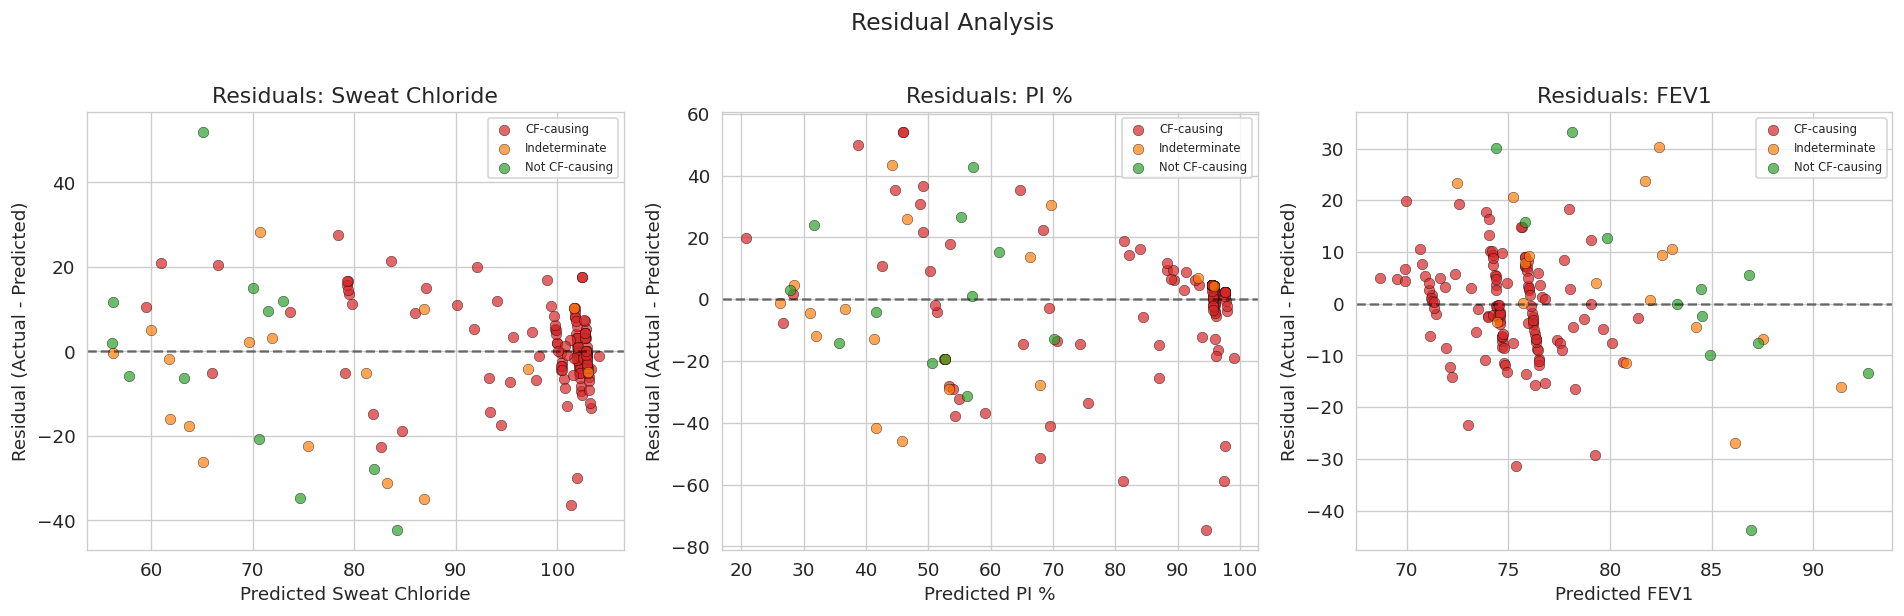

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

titles = ["Sweat Chloride", "PI %", "FEV1"]

for i, (target_name, title) in enumerate(zip(target_cols, titles)):
    ax = axes[i]
    res = results[target_name]

    residuals = res["y_true"] - res["y_pred"]

    # Plot residuals vs predicted
    for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
        mask = labels_for_plot == call_type
        ax.scatter(res["y_pred"][mask], residuals[mask],
                   c=call_colours[call_type], label=call_type, s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)

    ax.axhline(y=0, color="black", linestyle="--", alpha=0.5)
    ax.set_xlabel(f"Predicted {title}")
    ax.set_ylabel("Residual (Actual - Predicted)")
    ax.set_title(f"Residuals: {title}")
    ax.legend(fontsize=7)

plt.suptitle("Residual Analysis", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig15_residuals.png", dpi=300, bbox_inches="tight")
plt.show()




### Supervised vs unsupervised comparison


Predicted clinical values by unsupervised cluster:
        pred_sweat_cl       pred_fev1      pred_pi      
                 mean   std      mean  std    mean   std
cluster                                                 
0                96.1  10.3      75.3  2.6    82.3  20.2
1                75.9  14.6      79.7  5.5    49.7  18.7
2                99.0   8.0      75.0  3.1    88.9  14.2

Actual clinical values by unsupervised cluster:
        mean_sweat_cl       mean_fev1_pct_pred       pi_percent      
                 mean   std               mean   std       mean   std
cluster                                                              
0               101.4   8.4               66.7   8.7       90.3  16.4
1                64.2  14.6               85.5  12.1       31.2  16.8
2               100.8   6.1               77.1   6.4       91.1  15.7


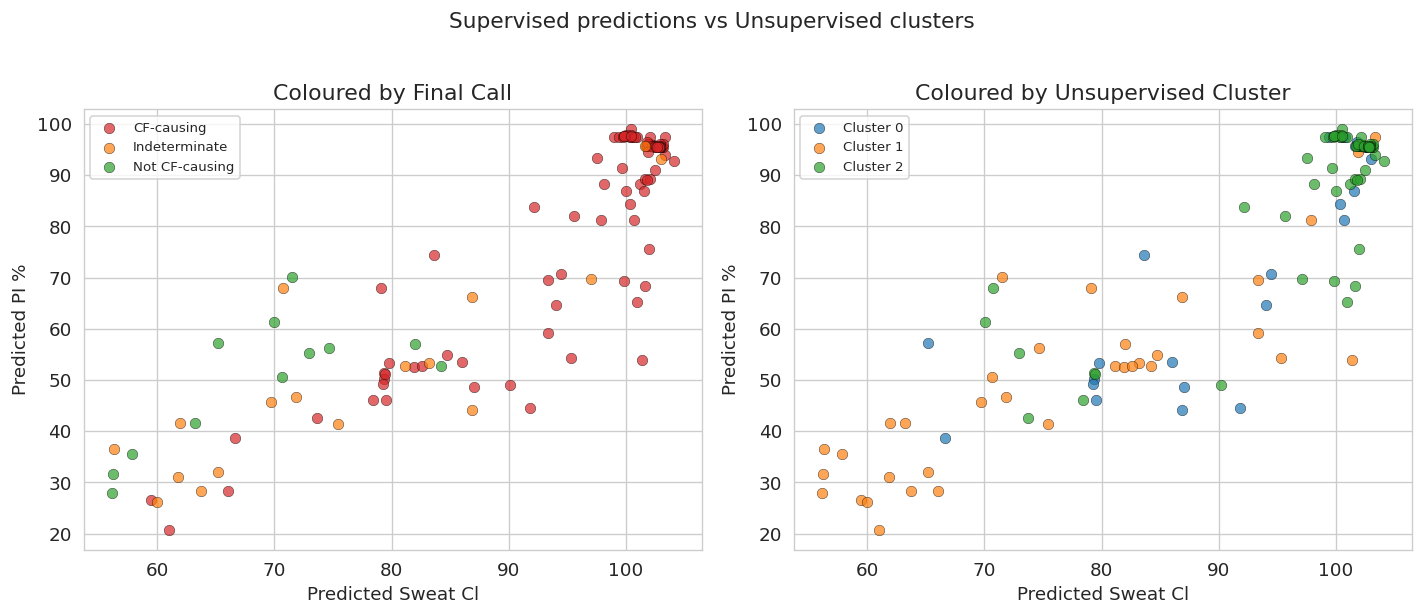

In [ ]:
# Get LOOCV predictions for sweat Cl
pred_sweat = results["mean_sweat_cl"]["y_pred"]
pred_fev1 = results["mean_fev1_pct_pred"]["y_pred"]
pred_pi = results["pi_percent"]["y_pred"]

# Add predictions to a temporary dataframe
df_supervised = df_clean.loc[complete_mask].copy()
df_supervised["pred_sweat_cl"] = pred_sweat
df_supervised["pred_fev1"] = pred_fev1
df_supervised["pred_pi"] = pred_pi

# Merge with cluster labels from Step 3
if "cluster_k3" in df_clinical.columns:
    # Map cluster labels to our supervised dataframe using variant_hgvs
    cluster_map = df_clinical.set_index("variant_hgvs")["cluster_k3"].to_dict()
    df_supervised["cluster"] = df_supervised["variant_hgvs"].map(cluster_map)

    print("Predicted clinical values by unsupervised cluster:")
    print("=" * 60)
    cluster_profile = df_supervised.groupby("cluster")[
        ["pred_sweat_cl", "pred_fev1", "pred_pi"]
    ].agg(["mean", "std"]).round(1)
    print(cluster_profile)

    print()
    print("Actual clinical values by unsupervised cluster:")
    print("=" * 60)
    actual_profile = df_supervised.groupby("cluster")[
        ["mean_sweat_cl", "mean_fev1_pct_pred", "pi_percent"]
    ].agg(["mean", "std"]).round(1)
    print(actual_profile)

    # Scatter plot: predicted sweat Cl coloured by cluster
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    cluster_palette = {0: "#1f77b4", 1: "#ff7f0e", 2: "#2ca02c"}

    # Left: coloured by final call
    ax = axes[0]
    for call_type in ["CF-causing", "Indeterminate", "Not CF-causing"]:
        mask = df_supervised["final_call"] == call_type
        ax.scatter(df_supervised.loc[mask, "pred_sweat_cl"],
                   df_supervised.loc[mask, "pred_pi"],
                   c=call_colours[call_type], label=call_type, s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)
    ax.set_xlabel("Predicted Sweat Cl")
    ax.set_ylabel("Predicted PI %")
    ax.set_title("Coloured by Final Call")
    ax.legend(fontsize=8)

    # Right: coloured by cluster
    ax = axes[1]
    for c in sorted(df_supervised["cluster"].dropna().unique()):
        mask = df_supervised["cluster"] == c
        ax.scatter(df_supervised.loc[mask, "pred_sweat_cl"],
                   df_supervised.loc[mask, "pred_pi"],
                   c=cluster_palette.get(int(c), "gray"), label=f"Cluster {int(c)}", s=40,
                   edgecolors="black", linewidth=0.3, alpha=0.7)
    ax.set_xlabel("Predicted Sweat Cl")
    ax.set_ylabel("Predicted PI %")
    ax.set_title("Coloured by Unsupervised Cluster")
    ax.legend(fontsize=8)

    plt.suptitle("Supervised predictions vs Unsupervised clusters", fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig("fig16_supervised_vs_unsupervised.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Cluster labels not found")


### Supervised summary


In [ ]:
print("SUPERVISED LEARNING SUMMARY")
print("=" * 50)
print(f"{'Target':<25} {'R\u00b2':>6} {'RMSE':>8} {'MAE':>8}")
print("-" * 50)
for name, res in results.items():
    print(f"{name:<25} {res['r2']:>6.3f} {res['rmse']:>8.1f} {res['mae']:>8.1f}")

best_target = max(results, key=lambda k: results[k]["r2"])
worst_target = min(results, key=lambda k: results[k]["r2"])
print(f"\nBest:  {best_target} (R\u00b2 = {results[best_target]['r2']:.3f})")
print(f"Worst: {worst_target} (R\u00b2 = {results[worst_target]['r2']:.3f})")



SUPERVISED LEARNING SUMMARY
Target                        R²     RMSE      MAE
--------------------------------------------------
mean_sweat_cl              0.506     12.6      8.7
pi_percent                 0.545     19.9     13.1
mean_fev1_pct_pred        -0.037     11.0      8.1

Best:  pi_percent (R² = 0.545)
Worst: mean_fev1_pct_pred (R² = -0.037)


---
# Model-Family Robustness — Single-Allele Model
The Random Forest is only one type of model, so we repeat the analysis with two very different ones to see whether the findings hold up. CatBoost is another tree-based model that builds its trees differently, and TabPFN is a pre-trained transformer designed for small datasets like this one. All three use the same features and targets, so agreement between them suggests the patterns come from the biology, not from any single method.

In [ ]:
# CatBoost + TabPFN (TabPFN pulls torch, already present in Colab)
!pip install catboost tabpfn --quiet
print("installed")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 727.9/727.9 kB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 3.1 MB/s eta 0:00:00
installed


In [ ]:
import numpy as np
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer
from catboost import CatBoostRegressor
import torch
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("TabPFN device:", DEVICE)

def make_catboost():
    # ~300 boosting rounds is plenty for 156 rows; verbose=0 keeps the log clean.
    return CatBoostRegressor(iterations=300, depth=6, learning_rate=0.05,
                             loss_function="RMSE", random_seed=42, verbose=0)

def make_tabpfn(ignore_limits=False):
    # v2 weights are Apache-2.0 — no login/licence popup needed.
    return TabPFNRegressor.create_default_for_version(ModelVersion.V2)

def scores(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred))

TabPFN device: cpu


In [ ]:
loo = LeaveOneOut()

# Reuse the Random Forest numbers already computed in the cell above (dict `results`).
single_family_results = {
    "Random Forest": {t: (results[t]["r2"], results[t]["rmse"], results[t]["mae"])
                      for t in target_cols}
}

# --- CatBoost: one model per target, LOOCV (fast) ---
print("Running CatBoost LOOCV ...")
single_family_results["CatBoost"] = {}
for i, t in enumerate(target_cols):
    ys = y[:, i]
    pred = np.empty_like(ys, dtype=float)
    for tr, te in loo.split(X):
        m = make_catboost().fit(X[tr], ys[tr])
        pred[te] = m.predict(X[te])
    single_family_results["CatBoost"][t] = scores(ys, pred)

# --- TabPFN: 5-fold CV (LOOCV would be 468 fits — very slow on CPU. On 156 rows,
#     5-fold gives an equivalent R2 estimate with ~30x fewer model fits) ---
from sklearn.model_selection import KFold
kf5 = KFold(n_splits=5, shuffle=True, random_state=42)
print("Running TabPFN 5-fold ...")
single_family_results["TabPFN"] = {}
for i, t in enumerate(target_cols):
    ys = y[:, i]
    pred = np.empty_like(ys, dtype=float)
    for tr, te in kf5.split(X):
        m = make_tabpfn().fit(X[tr], ys[tr])
        pred[te] = m.predict(X[te])
    single_family_results["TabPFN"][t] = scores(ys, pred)

# --- comparison tables ---
fams = list(single_family_results.keys())
print("\nSINGLE-ALLELE — R2 by model family (LOOCV)")
print(f"{'Target':<22}" + "".join(f"{f:>15}" for f in fams))
print("-" * (22 + 15 * len(fams)))
for t in target_cols:
    print(f"{t:<22}" + "".join(f"{single_family_results[f][t][0]:>15.3f}" for f in fams))

print("\nFull metrics (R2 / RMSE / MAE):")
for f in fams:
    print(f"\n{f}:")
    print(f"  {'Target':<22}{'R2':>8}{'RMSE':>8}{'MAE':>8}")
    for t in target_cols:
        r2, rmse, mae = single_family_results[f][t]
        print(f"  {t:<22}{r2:>8.3f}{rmse:>8.1f}{mae:>8.1f}")

Running CatBoost LOOCV ...
Running TabPFN 5-fold ...


tabpfn-v2-regressor.ckpt: reconstructing file:   0%|          |  0.00B / 44.4MB            

tabpfn-v2-regressor.ckpt: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]


SINGLE-ALLELE — R2 by model family (LOOCV)
Target                  Random Forest       CatBoost         TabPFN
-------------------------------------------------------------------
mean_sweat_cl                   0.506          0.512          0.546
pi_percent                      0.545          0.573          0.551
mean_fev1_pct_pred             -0.037         -0.028         -0.004

Full metrics (R2 / RMSE / MAE):

Random Forest:
  Target                      R2    RMSE     MAE
  mean_sweat_cl            0.506    12.6     8.7
  pi_percent               0.545    19.9    13.1
  mean_fev1_pct_pred      -0.037    11.0     8.1

CatBoost:
  Target                      R2    RMSE     MAE
  mean_sweat_cl            0.512    12.5     8.7
  pi_percent               0.573    19.3    13.1
  mean_fev1_pct_pred      -0.028    11.0     8.2

TabPFN:
  Target                      R2    RMSE     MAE
  mean_sweat_cl            0.546    12.1     8.4
  pi_percent               0.551    19.8    13.6
  mean_f

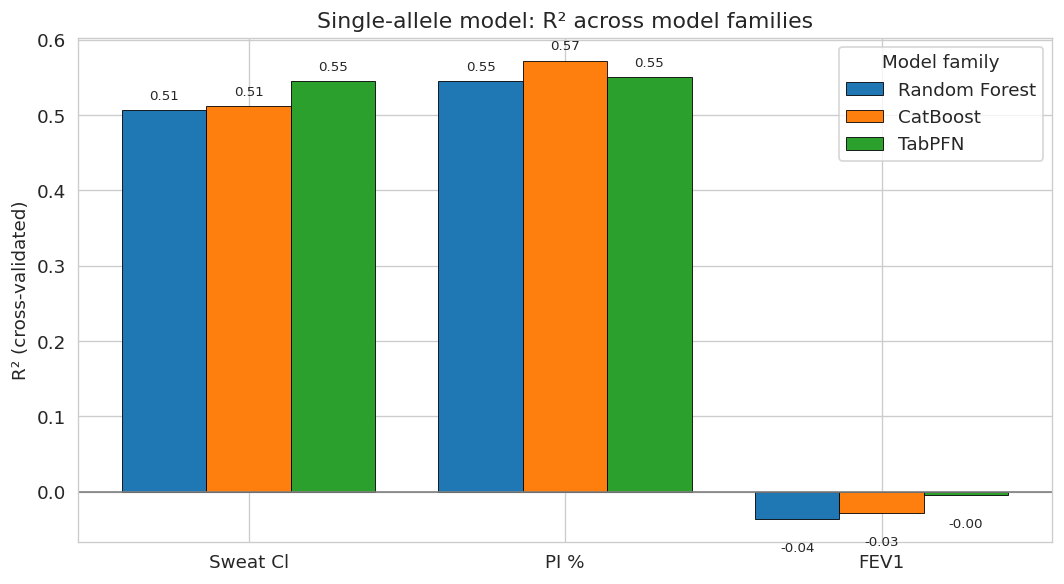

In [ ]:
import matplotlib.pyplot as plt

fams = list(single_family_results.keys())
short = ["Sweat Cl", "PI %", "FEV1"]
xpos = np.arange(len(target_cols))
width = 0.8 / len(fams)

fig, ax = plt.subplots(figsize=(9, 5))
for j, f in enumerate(fams):
    vals = [single_family_results[f][t][0] for t in target_cols]
    bars = ax.bar(xpos + j * width, vals, width, label=f, edgecolor="black", linewidth=0.5)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + (0.01 if v >= 0 else -0.03),
                f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)

ax.axhline(0, color="grey", lw=1)
ax.set_xticks(xpos + width * (len(fams) - 1) / 2)
ax.set_xticklabels(short)
ax.set_ylabel("R² (cross-validated)")
ax.set_title("Single-allele model: R² across model families")
ax.legend(title="Model family")
plt.tight_layout()
plt.savefig("fig_family_single.png", dpi=150, bbox_inches="tight")
plt.show()

---
# Genotype Pair Analysis
Every CF patient carries two CFTR alleles. The milder allele sets the floor
(minimum function rule), so pair severity ≈ min(allele1, allele2) for sweat Cl and PI,
max for FEV1.


### Generate pairs
Order-invariant features: each pair described by min/max across the two alleles,
so pred(A,B) = pred(B,A) by construction.


In [ ]:
from itertools import combinations_with_replacement

# We need variants that have clinical data for the minimum function rule.
# reset_index gives clean positions 0..n-1 that we use to group later.
df_for_pairs = df_clean.dropna(
    subset=["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred"]
).copy()
df_for_pairs = df_for_pairs.reset_index(drop=True)
n_variants = len(df_for_pairs)

print(f"Variants with complete clinical data: {n_variants}")
print(f"Possible unique pairs: {n_variants * (n_variants + 1) // 2}")
print()

pairs = list(combinations_with_replacement(range(n_variants), 2))
print(f"Generated {len(pairs)} unique pairs")


def symmetric_lo_hi(v1, v2):
    """Order-invariant summary of two allele values.
    Returns (min, max), so swapping the two alleles gives the SAME result.
    Missing data: if one value is NaN we use the value we DO have for both;
    if both are NaN we leave NaN for the imputer to fill in later."""
    if pd.isna(v1) and pd.isna(v2):
        return np.nan, np.nan
    if pd.isna(v1):
        return v2, v2
    if pd.isna(v2):
        return v1, v1
    return min(v1, v2), max(v1, v2)


pair_records = []

for idx1, idx2 in pairs:
    row1 = df_for_pairs.iloc[idx1]
    row2 = df_for_pairs.iloc[idx2]

    record = {
        "allele1_idx": idx1,          # position of allele 1 in df_for_pairs
        "allele2_idx": idx2,          # position of allele 2 in df_for_pairs
        "allele1_hgvs": row1["variant_hgvs"],
        "allele2_hgvs": row2["variant_hgvs"],
        "allele1_legacy": row1["variant_legacy"],
        "allele2_legacy": row2["variant_legacy"],

        # Pair clinical values using the minimum function rule
        "pair_sweat_cl": min(row1["mean_sweat_cl"], row2["mean_sweat_cl"]),
        "pair_fev1": max(row1["mean_fev1_pct_pred"], row2["mean_fev1_pct_pred"]),
        "pair_pi": min(row1["pi_percent"], row2["pi_percent"]),
    }

    # ORDER-INVARIANT features.
    # For every feature we keep its min and its max across the two alleles.
    # Because min()/max() ignore order, the pair (A,B) and the pair (B,A) get
    # IDENTICAL features. The model therefore cannot depend on allele order, and
    # the severity heatmap comes out symmetric by construction.
    #   - For the continuous lab/computational features this mirrors the
    #     biology of the minimum function rule (one allele sets the floor).
    #   - For the one-hot variant-type columns, max_=1 means "at least one allele
    #     is this type" and min_=1 means "both alleles are this type".
    for feat in available_features:
        lo, hi = symmetric_lo_hi(row1[feat], row2[feat])
        record[f"min_{feat}"] = lo
        record[f"max_{feat}"] = hi

    pair_records.append(record)

df_pairs = pd.DataFrame(pair_records)
print(f"\nPair dataframe: {df_pairs.shape[0]} pairs x {df_pairs.shape[1]} columns")
print()
print("Sample pairs (first 5):")
print(df_pairs[["allele1_legacy", "allele2_legacy", "pair_sweat_cl", "pair_fev1", "pair_pi"]].head())


Variants with complete clinical data: 156
Possible unique pairs: 12246

Generated 12246 unique pairs

Pair dataframe: 12246 pairs x 35 columns

Sample pairs (first 5):
  allele1_legacy allele2_legacy  pair_sweat_cl  pair_fev1  pair_pi
0       1078delT       1078delT           97.0       73.6     98.6
1       1078delT      1154insTC           97.0       73.6     98.6
2       1078delT       1213delT           97.0       83.1     98.6
3       1078delT     1248+1G->A           97.0       73.6     98.6
4       1078delT       1259insA           97.0       79.4     98.6


### Pair-level distributions


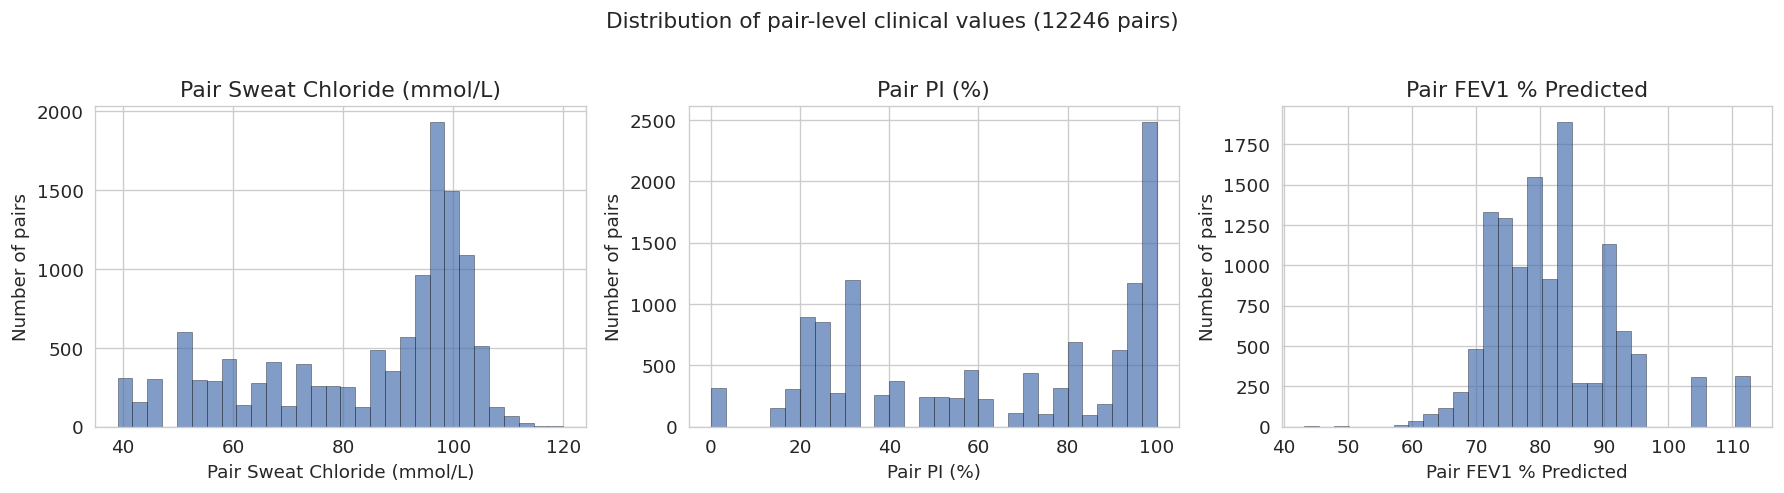

Pair-level summary statistics:
       pair_sweat_cl  pair_pi  pair_fev1
count        12246.0  12246.0    12246.0
mean            83.7     62.5       81.9
std             19.6     31.9        9.7
min             39.0      0.0       43.2
25%             67.0     30.0       74.4
50%             93.0     66.7       80.7
75%             99.0     95.7       87.4
max            120.0    100.0      112.8


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (col, title) in enumerate([
    ("pair_sweat_cl", "Pair Sweat Chloride (mmol/L)"),
    ("pair_pi", "Pair PI (%)"),
    ("pair_fev1", "Pair FEV1 % Predicted"),
]):
    ax = axes[i]
    ax.hist(df_pairs[col], bins=30, color="#4C72B0", edgecolor="black", linewidth=0.3, alpha=0.7)
    ax.set_xlabel(title)
    ax.set_ylabel("Number of pairs")
    ax.set_title(title)

plt.suptitle(f"Distribution of pair-level clinical values ({len(df_pairs)} pairs)", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("fig17_pair_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

print("Pair-level summary statistics:")
print(df_pairs[["pair_sweat_cl", "pair_pi", "pair_fev1"]].describe().round(1))


### Pair model — variant-grouped CV
~12,000 pairs from ~156 variants means a naive random split would let the same
allele appear in train and test. We split at the variant level instead: test pairs
must have *both* alleles in the held-out fold. Imputer sits inside the Pipeline
so train-fold medians don't leak into test.


In [ ]:
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline

# ---- 1. Feature and target columns ----
pair_feature_cols = (
    [f"min_{feat}" for feat in available_features]
    + [f"max_{feat}" for feat in available_features]
)

pair_target_names = ["pair_sweat_cl", "pair_pi", "pair_fev1"]
pair_display_names = ["Sweat Chloride", "PI %", "FEV1"]

# Note: X_pairs still contains NaN here on purpose. The imputer lives inside the
# Pipeline below, so it is fitted on the training fold only (no leakage).
X_pairs = df_pairs[pair_feature_cols].values
y_pairs = df_pairs[pair_target_names].values

print(f"Pair feature matrix: {X_pairs.shape}")
print(f"Pair target matrix:  {y_pairs.shape}")
print()

#  Assign each UNIQUE variant to one of 5 folds
# The split is done on variants, NOT on pairs, so an allele can never end up in
# both training and test at the same time.
n_splits = 5
variant_kfold = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# variant_fold[v] = which fold (0..4) variant position v belongs to
variant_fold = np.empty(n_variants, dtype=int)
for fold_id, (_, test_variant_idx) in enumerate(variant_kfold.split(np.arange(n_variants))):
    variant_fold[test_variant_idx] = fold_id

# Look up the fold of each allele in every pair
a1_fold = variant_fold[df_pairs["allele1_idx"].values]
a2_fold = variant_fold[df_pairs["allele2_idx"].values]

# ---- 3. Variant-grouped cross-validation ----
# For each target we collect predictions only for pairs whose BOTH alleles were
# held out, then score those honest held-out predictions.
pair_results = {}

for i, (target_name, display_name) in enumerate(zip(pair_target_names, pair_display_names)):
    print(f"Training pair model for: {display_name} (variant-grouped CV)...")

    y_single = y_pairs[:, i]

    true_collected = []
    pred_collected = []

    for fold_id in range(n_splits):
        # Test pairs: BOTH alleles in the held-out fold
        test_mask = (a1_fold == fold_id) & (a2_fold == fold_id)
        # Train pairs: BOTH alleles NOT in the held-out fold
        train_mask = (a1_fold != fold_id) & (a2_fold != fold_id)

        if test_mask.sum() == 0:
            continue

        # Pipeline: impute (fit on train only) then Random Forest
        pipe = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("rf", RandomForestRegressor(
                n_estimators=200,       # fewer trees since we have more data
                max_depth=15,           # limit depth to prevent overfitting
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipe.fit(X_pairs[train_mask], y_single[train_mask])
        fold_pred = pipe.predict(X_pairs[test_mask])

        true_collected.append(y_single[test_mask])
        pred_collected.append(fold_pred)

    # Pool all held-out predictions (folds are disjoint at the variant level,
    # so no pair is scored twice).
    y_true_cv = np.concatenate(true_collected)
    y_pred_cv = np.concatenate(pred_collected)

    r2 = r2_score(y_true_cv, y_pred_cv)
    rmse = np.sqrt(mean_squared_error(y_true_cv, y_pred_cv))
    mae = mean_absolute_error(y_true_cv, y_pred_cv)

    pair_results[target_name] = {
        "y_true": y_true_cv,
        "y_pred": y_pred_cv,
        "r2": r2,
        "rmse": rmse,
        "mae": mae,
        "n_scored": len(y_true_cv),
    }

    coverage = 100 * len(y_true_cv) / len(df_pairs)
    print(f"  scored {len(y_true_cv)} held-out pairs ({coverage:.0f}% of all pairs)")
    print(f"  R² = {r2:.3f}, RMSE = {rmse:.1f}, MAE = {mae:.1f}")
    print()

print(f"\nPAIR MODEL SUMMARY (variant-grouped CV — honest generalisation):")
print(f"{'Target':<20} {'R²':>6} {'RMSE':>8} {'MAE':>8}")
print("-" * 45)
for name, res in pair_results.items():
    print(f"{name:<20} {res['r2']:>6.3f} {res['rmse']:>8.1f} {res['mae']:>8.1f}")

print(f"\n\nCOMPARISON — Single allele vs Pair models:")
print(f"{'Target':<25} {'Single R²':>10} {'Pair R²':>10}")
print("-" * 48)
single_names = ["mean_sweat_cl", "pi_percent", "mean_fev1_pct_pred"]
for s_name, p_name in zip(single_names, pair_target_names):
    s_r2 = results[s_name]["r2"]
    p_r2 = pair_results[p_name]["r2"]
    print(f"{s_name:<25} {s_r2:>10.3f} {p_r2:>10.3f}")


Pair feature matrix: (12246, 26)
Pair target matrix:  (12246, 3)

Training pair model for: Sweat Chloride (variant-grouped CV)...
  scored 2512 held-out pairs (21% of all pairs)
  R² = 0.328, RMSE = 16.0, MAE = 11.8

Training pair model for: PI % (variant-grouped CV)...
  scored 2512 held-out pairs (21% of all pairs)
  R² = 0.271, RMSE = 27.2, MAE = 19.6

Training pair model for: FEV1 (variant-grouped CV)...
  scored 2512 held-out pairs (21% of all pairs)
  R² = -0.495, RMSE = 12.0, MAE = 9.0


PAIR MODEL SUMMARY (variant-grouped CV — honest generalisation):
Target                   R²     RMSE      MAE
---------------------------------------------
pair_sweat_cl         0.328     16.0     11.8
pair_pi               0.271     27.2     19.6
pair_fev1            -0.495     12.0      9.0


COMPARISON — Single allele vs Pair models:
Target                     Single R²    Pair R²
------------------------------------------------
mean_sweat_cl                  0.506      0.328
pi_percent     

### Pair predictions — predicted vs actual


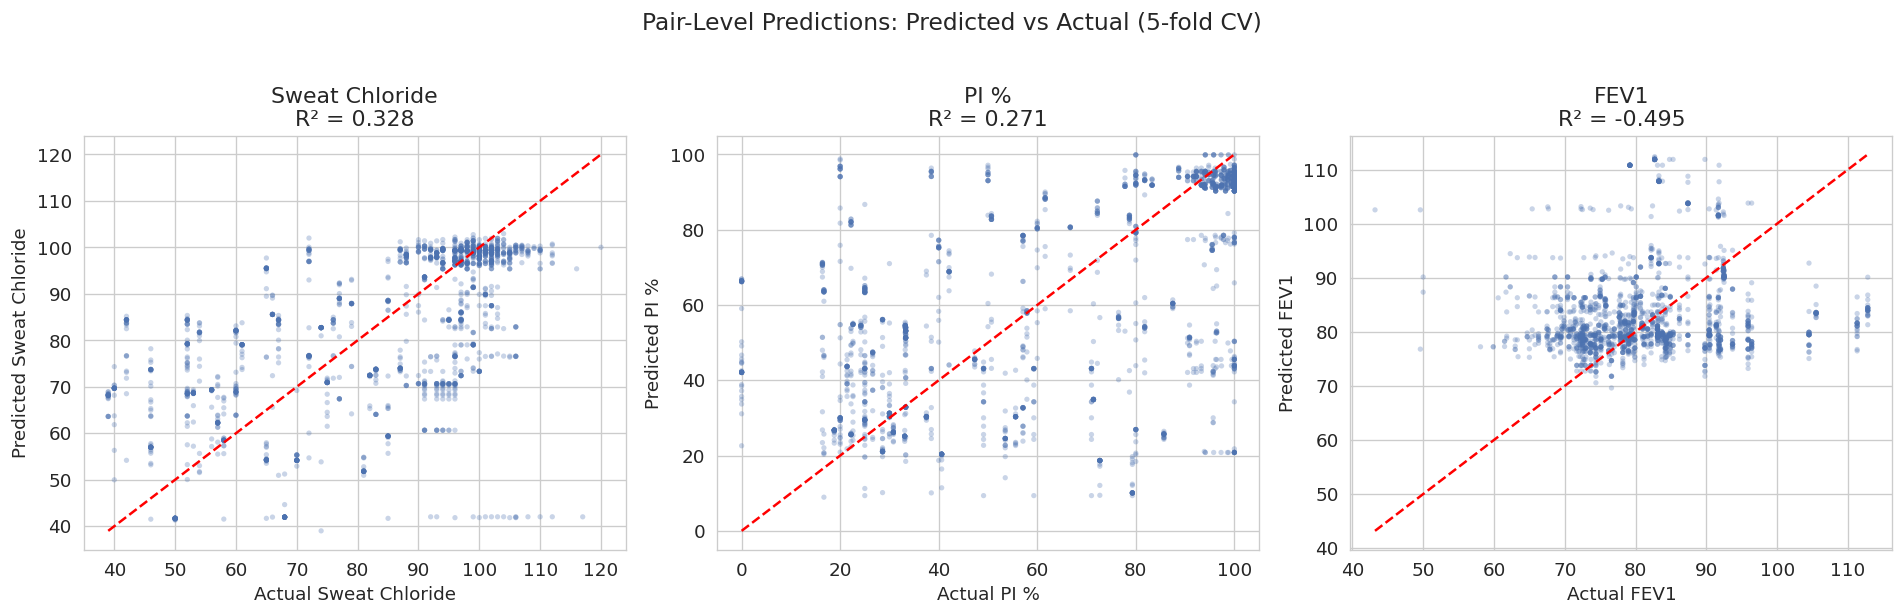

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, (target_name, display_name) in enumerate(zip(pair_target_names, pair_display_names)):
    ax = axes[i]
    res = pair_results[target_name]

    # Sample 2000 points for readability (plotting 12k dots is messy)
    n_sample = min(2000, len(res["y_true"]))
    rng = np.random.RandomState(42)
    idx = rng.choice(len(res["y_true"]), n_sample, replace=False)

    ax.scatter(res["y_true"][idx], res["y_pred"][idx],
               c="#4C72B0", s=10, alpha=0.3, edgecolors="none")

    # Perfect prediction line
    min_val = min(res["y_true"].min(), res["y_pred"].min())
    max_val = max(res["y_true"].max(), res["y_pred"].max())
    ax.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5)

    ax.set_xlabel(f"Actual {display_name}")
    ax.set_ylabel(f"Predicted {display_name}")
    ax.set_title(f"{display_name}\nR² = {res['r2']:.3f}")

plt.suptitle("Pair-Level Predictions: Predicted vs Actual (5-fold CV)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("fig18_pair_predicted_vs_actual.png", dpi=300, bbox_inches="tight")
plt.show()


---
# Model-Family Robustness — Genotype-Pair Model
Because TabPFN is designed for small tabular datasets, the genotype-pair analysis required an adjustment. Although roughly 12,000 pairs exist, they contain little additional information, since each is derived by taking the milder and more severe value from two of the original 156 variants. For TabPFN, each training fold was therefore reduced to a random sample of 1,000 pairs. This affected only the training data; test pairs were left intact with both variants fully held out, preserving the integrity of the variant-grouped evaluation. Random Forest and CatBoost were trained on the complete folds.

In [ ]:
# Re-import here so this section runs even if the single-allele section above was skipped.
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor
import torch
from tabpfn import TabPFNRegressor
from tabpfn.constants import ModelVersion
import os
os.environ["TABPFN_ALLOW_CPU_LARGE_DATASET"] = "1"  # allow CPU (we keep the subsample small)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def scores(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred))

def make_catboost_pairs():
    return CatBoostRegressor(iterations=300, depth=8, learning_rate=0.05,
                             loss_function="RMSE", random_seed=42, verbose=0)

def make_tabpfn(ignore_limits=False):
    # v2 weights are Apache-2.0 — no login/licence popup needed.
    return TabPFNRegressor.create_default_for_version(ModelVersion.V2)

TABPFN_MAX_TRAIN = 1000            # cap per training fold for TabPFN (CPU-friendly)
_rng = np.random.RandomState(42)

def run_pair_family(make_model, name, subsample=None):
    """Run one model family through the SAME variant-grouped folds used for the RF pair
    model (reuses a1_fold, a2_fold, n_splits from the pair CV cell above)."""
    print(f"{name}: variant-grouped {n_splits}-fold CV ...")
    out = {}
    for i, target_name in enumerate(pair_target_names):
        ys = y_pairs[:, i]
        true_c, pred_c = [], []
        for fold_id in range(n_splits):
            test_mask  = (a1_fold == fold_id) & (a2_fold == fold_id)
            train_mask = (a1_fold != fold_id) & (a2_fold != fold_id)
            if test_mask.sum() == 0:
                continue
            tr_idx = np.where(train_mask)[0]
            if subsample is not None and len(tr_idx) > subsample:
                tr_idx = _rng.choice(tr_idx, size=subsample, replace=False)  # train-only
            imp = SimpleImputer(strategy="median")
            X_tr = imp.fit_transform(X_pairs[tr_idx])       # fit on train fold only
            X_te = imp.transform(X_pairs[test_mask])
            m = make_model()
            m.fit(X_tr, ys[tr_idx])
            true_c.append(ys[test_mask])
            pred_c.append(m.predict(X_te))
        y_true = np.concatenate(true_c)
        y_pred = np.concatenate(pred_c)
        out[target_name] = scores(y_true, y_pred)
        r2, rmse, mae = out[target_name]
        print(f"  {target_name:<16} R2={r2:>7.3f}  RMSE={rmse:>5.1f}  MAE={mae:>5.1f}  (n={len(y_true)})")
    print()
    return out

# Reuse the RF pair numbers from the variant-grouped CV cell (dict `pair_results`).
pair_family_results = {
    "Random Forest": {t: (pair_results[t]["r2"], pair_results[t]["rmse"], pair_results[t]["mae"])
                      for t in pair_target_names}
}
pair_family_results["CatBoost"] = run_pair_family(make_catboost_pairs, "CatBoost")
pair_family_results["TabPFN"]   = run_pair_family(lambda: make_tabpfn(ignore_limits=True),
                                                  "TabPFN", subsample=TABPFN_MAX_TRAIN)

# --- comparison table ---
fams = list(pair_family_results.keys())
print("PAIR MODEL — R2 by model family (variant-grouped CV)")
print(f"{'Target':<16}" + "".join(f"{f:>15}" for f in fams))
print("-" * (16 + 15 * len(fams)))
for t in pair_target_names:
    print(f"{t:<16}" + "".join(f"{pair_family_results[f][t][0]:>15.3f}" for f in fams))

CatBoost: variant-grouped 5-fold CV ...
  pair_sweat_cl    R2=  0.491  RMSE= 14.0  MAE= 10.5  (n=2512)
  pair_pi          R2=  0.442  RMSE= 23.8  MAE= 17.6  (n=2512)
  pair_fev1        R2= -0.092  RMSE= 10.3  MAE=  7.9  (n=2512)

TabPFN: variant-grouped 5-fold CV ...
  pair_sweat_cl    R2=  0.382  RMSE= 15.4  MAE= 11.4  (n=2512)
  pair_pi          R2=  0.465  RMSE= 23.3  MAE= 16.6  (n=2512)
  pair_fev1        R2= -0.210  RMSE= 10.8  MAE=  8.4  (n=2512)

PAIR MODEL — R2 by model family (variant-grouped CV)
Target            Random Forest       CatBoost         TabPFN
-------------------------------------------------------------
pair_sweat_cl             0.328          0.491          0.382
pair_pi                   0.271          0.442          0.465
pair_fev1                -0.495         -0.092         -0.210


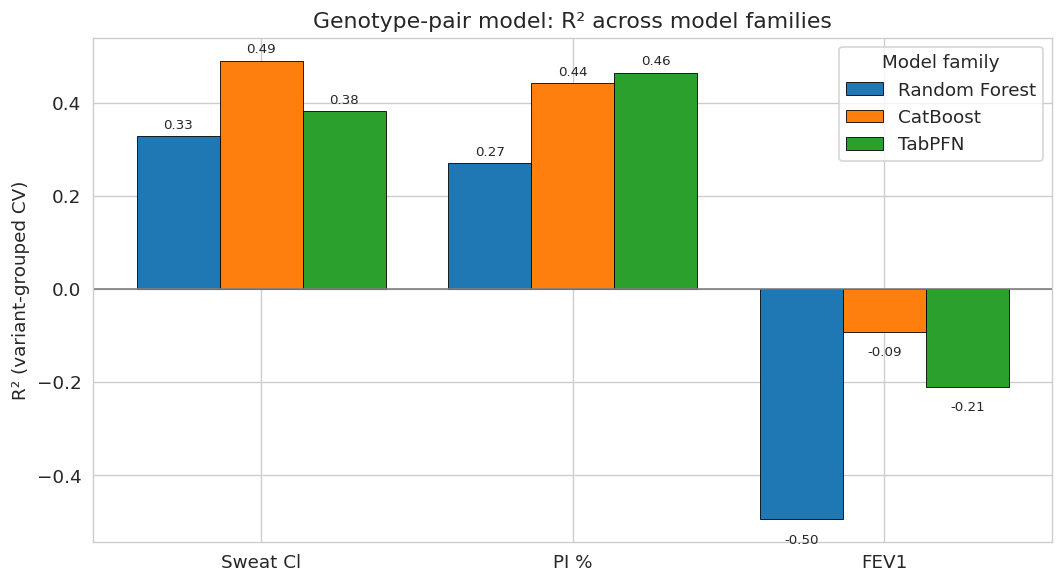

In [ ]:
import matplotlib.pyplot as plt

fams = list(pair_family_results.keys())
short = ["Sweat Cl", "PI %", "FEV1"]
xpos = np.arange(len(pair_target_names))
width = 0.8 / len(fams)

fig, ax = plt.subplots(figsize=(9, 5))
for j, f in enumerate(fams):
    vals = [pair_family_results[f][t][0] for t in pair_target_names]
    bars = ax.bar(xpos + j * width, vals, width, label=f, edgecolor="black", linewidth=0.5)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + (0.01 if v >= 0 else -0.03),
                f"{v:.2f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)

ax.axhline(0, color="grey", lw=1)
ax.set_xticks(xpos + width * (len(fams) - 1) / 2)
ax.set_xticklabels(short)
ax.set_ylabel("R² (variant-grouped CV)")
ax.set_title("Genotype-pair model: R² across model families")
ax.legend(title="Model family")
plt.tight_layout()
plt.savefig("fig_family_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

### Severity heatmap (top 20 variants)


Top 20 variants by allele frequency:
  F508del              n=49740
  G542X                n=1856
  G551D                n=1427
  N1303K               n=1242
  W1282X               n=1056
  621+1G->T            n=817
  R117H                n=808
  R553X                n=645
  1717-1G->A           n=635
  2789+5G->A           n=538
  3849+10kbC->T        n=524
  2183AA->G            n=377
  R1162X               n=346
  I507del              n=319
  G85E                 n=316
  CFTRdele2,3          n=277
  3120+1G->A           n=266
  3659delC             n=248
  1898+1G->A           n=245
  R347P                n=234


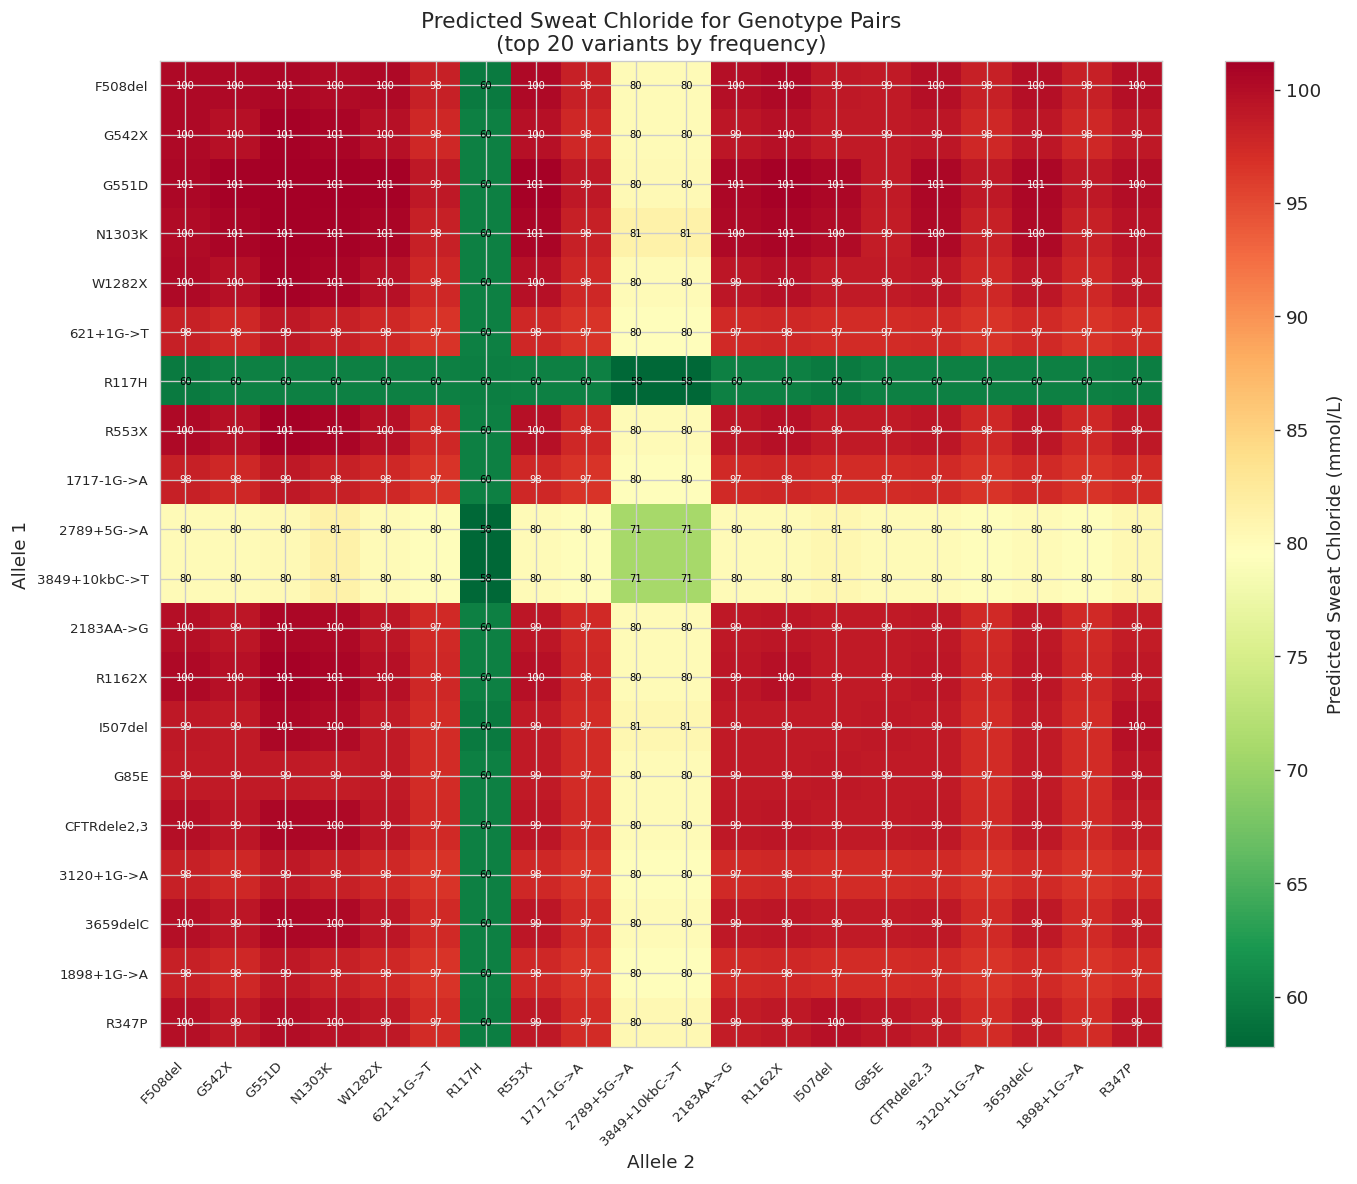

In [ ]:
# full-data model for the heatmap (display only, not evaluation)
pair_imputer = SimpleImputer(strategy="median")
X_pairs_imputed = pair_imputer.fit_transform(X_pairs)

rf_final = RandomForestRegressor(
    n_estimators=200, max_depth=15, min_samples_split=10,
    min_samples_leaf=5, random_state=42, n_jobs=-1
)
rf_final.fit(X_pairs_imputed, y_pairs[:, 0])  # sweat Cl

top_n = 20
top_variants = df_for_pairs.nlargest(top_n, "n_alleles")
top_names = top_variants["variant_legacy"].values
top_indices = top_variants.index.tolist()

print(f"Top {top_n} variants by allele frequency:")
for _, row in top_variants[["variant_legacy", "n_alleles"]].iterrows():
    print(f"  {row['variant_legacy']:<20} n={int(row['n_alleles'])}")

heatmap_data = np.zeros((top_n, top_n))

for i in range(top_n):
    for j in range(top_n):
        row_i, row_j = top_variants.iloc[i], top_variants.iloc[j]
        lo_feats, hi_feats = [], []
        for feat in available_features:
            lo, hi = symmetric_lo_hi(row_i[feat], row_j[feat])
            lo_feats.append(lo)
            hi_feats.append(hi)
        pf = np.array(lo_feats + hi_feats).reshape(1, -1)
        pf = pair_imputer.transform(pf)
        heatmap_data[i, j] = rf_final.predict(pf)[0]

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(heatmap_data, cmap="RdYlGn_r", aspect="auto")

ax.set_xticks(range(top_n))
ax.set_xticklabels(top_names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_names, fontsize=8)

for i in range(top_n):
    for j in range(top_n):
        ax.text(j, i, f"{heatmap_data[i, j]:.0f}", ha="center", va="center",
                fontsize=6, color="white" if heatmap_data[i, j] > 90 else "black")

plt.colorbar(im, ax=ax, label="Predicted Sweat Chloride (mmol/L)")
ax.set_title("Predicted Sweat Chloride for Genotype Pairs\n(top 20 variants by frequency)", fontsize=13)
ax.set_xlabel("Allele 2")
ax.set_ylabel("Allele 1")
plt.tight_layout()
plt.savefig("fig19_pair_severity_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


### Held-out validation
Remove F508del, G551D, R117H from training entirely, then predict their
pairwise genotypes. True out-of-sample test.


In [ ]:
TABPFN_MAX_TRAIN = 1000

known_genotypes = [
    ("F508del", "F508del", "Severe",        "95-115"),
    ("F508del", "G551D",   "Severe",        "90-110"),
    ("F508del", "R117H",   "Mild-Moderate", "40-80"),
    ("G551D",   "G551D",   "Severe",        "95-115"),
    ("R117H",   "R117H",   "Mild",          "30-60"),
]

# hold out all pairs containing these alleles
validation_names = ["F508del", "G551D", "R117H"]

heldout_hgvs = set()
for name in validation_names:
    matches = df_for_pairs[df_for_pairs["variant_legacy"].str.contains(name, na=False)]
    if len(matches) > 0:
        heldout_hgvs.add(matches.iloc[0]["variant_hgvs"])

is_heldout_pair = (df_pairs["allele1_hgvs"].isin(heldout_hgvs)
                   | df_pairs["allele2_hgvs"].isin(heldout_hgvs))
train_mask = ~is_heldout_pair

print(f"Held-out alleles: {validation_names}")
print(f"Pairs removed from training: {is_heldout_pair.sum()}")
print(f"Pairs used for training:     {train_mask.sum()}\n")

X_tr = X_pairs[train_mask.values]
y_tr = y_pairs[train_mask.values, 0]


def make_rf():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=200, max_depth=15, min_samples_split=10,
            min_samples_leaf=5, random_state=42, n_jobs=-1))
    ])


def make_cat():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", CatBoostRegressor(
            iterations=500, depth=6, learning_rate=0.05,
            random_seed=42, verbose=0))
    ])


def make_tabpfn():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("model", TabPFNRegressor.create_default_for_version(ModelVersion.V2))
    ])


fitted = {}
for label, factory in [("Random Forest", make_rf),
                       ("CatBoost", make_cat),
                       ("TabPFN", make_tabpfn)]:
    Xf, yf = X_tr, y_tr
    if label == "TabPFN" and len(Xf) > TABPFN_MAX_TRAIN:
        idx = np.random.RandomState(42).choice(len(Xf), TABPFN_MAX_TRAIN, replace=False)
        Xf, yf = Xf[idx], yf[idx]
    m = factory()
    m.fit(Xf, yf)
    fitted[label] = m
    print(f"{label}: fitted on {len(Xf)} pairs")

print("\nVALIDATION: predictions vs known clinical data (held-out alleles)")
print("=" * 92)
print(f"{'Genotype':<20} {'RF':>8} {'CatBoost':>10} {'TabPFN':>9} "
      f"{'Expected':>12} {'Severity':>17}")
print("-" * 92)

for a1_name, a2_name, severity, expected_range in known_genotypes:
    a1_match = df_for_pairs[df_for_pairs["variant_legacy"].str.contains(a1_name, na=False)]
    a2_match = df_for_pairs[df_for_pairs["variant_legacy"].str.contains(a2_name, na=False)]
    genotype_label = f"{a1_name}/{a2_name}"

    if len(a1_match) > 0 and len(a2_match) > 0:
        row1, row2 = a1_match.iloc[0], a2_match.iloc[0]
        lo_feats, hi_feats = [], []
        for feat in available_features:
            lo, hi = symmetric_lo_hi(row1[feat], row2[feat])
            lo_feats.append(lo)
            hi_feats.append(hi)
        pf = np.array(lo_feats + hi_feats, dtype=float).reshape(1, -1)
        p = [float(fitted[k].predict(pf)[0])
             for k in ["Random Forest", "CatBoost", "TabPFN"]]
        print(f"{genotype_label:<20} {p[0]:>8.1f} {p[1]:>10.1f} {p[2]:>9.1f} "
              f"{expected_range:>12} {severity:>17}")
    else:
        print(f"{genotype_label:<20} {'N/A':>8} {'N/A':>10} {'N/A':>9} "
              f"{expected_range:>12} {severity:>17}")

print(" These alleles were not in the training data, so this is a true out-of-sample test")

Held-out alleles: ['F508del', 'G551D', 'R117H']
Pairs removed from training: 465
Pairs used for training:     11781

Random Forest: fitted on 11781 pairs
CatBoost: fitted on 11781 pairs
TabPFN: fitted on 1000 pairs

VALIDATION: predictions vs known clinical data (held-out alleles)
Genotype                   RF   CatBoost    TabPFN     Expected          Severity
--------------------------------------------------------------------------------------------
F508del/F508del          97.1       95.7      94.5       95-115            Severe
F508del/G551D            96.7       98.5      94.8       90-110            Severe
F508del/R117H            67.5       70.6      65.0        40-80     Mild-Moderate
G551D/G551D              98.7      101.0      95.4       95-115            Severe
R117H/R117H              67.4       64.5      62.4        30-60              Mild

Interpretation:
- These alleles were NOT in the training data, so this is a true out-of-sample test
- Two severe alleles should pred